<a href="https://colab.research.google.com/github/butthamza20/ECS708U-P-Fashion-MNIST-Coursework/blob/main/ECS708U_P_Fashion_MNIST_Coursework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ECS708U Fashion-MNIST Coursework

**Repository:** https://github.com/butthamza20/ECS708U-P-Fashion-MNIST-Coursework

A study of Fashion-MNIST [1] in six parts. Training data fits models, validation chooses settings, and the test set
is used once at the end (R1, R2, R6). All results come from one CPU run with seed 42.

# Part 0: Data

**Objective:** create fixed, reproducible partitions before training any model.

## 0.1 Fixed data partitions

### Importing libraries

In [ ]:
# Standard library
import os
import sys
import time
import random
import copy

# Numerical, plotting and table libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# PyTorch: loading Fashion-MNIST, building DataLoaders and networks
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader, TensorDataset

# scikit-learn: splitting, scaling, models, clustering and metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay,
                             silhouette_score, adjusted_rand_score)

# SciPy: hierarchical clustering
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

### Setup: random seeds and hardware

In [ ]:
# One seed for the whole notebook
SEED = 42

# Seed every random number generator used below
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Record the software versions and hardware for reproducibility
import sklearn, scipy, matplotlib

print("Python version:       ", sys.version.split()[0])
print("PyTorch version:      ", torch.__version__)
print("Torchvision version:  ", torchvision.__version__)
print("NumPy version:        ", np.__version__)
print("scikit-learn version: ", sklearn.__version__)
print("SciPy version:        ", scipy.__version__)
print("pandas version:       ", pd.__version__)
print("Matplotlib version:   ", matplotlib.__version__)

if torch.cuda.is_available():
    print("Device: GPU -", torch.cuda.get_device_name(0))
else:
    print("Device: CPU (no GPU available)")

# Device for any later PyTorch training (GPU if available, otherwise CPU)
device = "cuda" if torch.cuda.is_available() else "cpu"

Python version:        3.13.18
PyTorch version:       2.14.1+cpu
Torchvision version:   0.29.1+cpu
NumPy version:         2.4.6
scikit-learn version:  1.6.1
SciPy version:         1.16.3
pandas version:        2.2.3
Matplotlib version:    3.10.0
Device: CPU (no GPU available)


### Loading the training set

In [ ]:
# Download (if needed) and load the 60,000 official training images
train_data = datasets.FashionMNIST(root='data', train=True, download=True, transform=transforms.ToTensor())

train_data_length = len(train_data)
print("\nTraining images:", train_data_length)
print("Classes:", train_data.classes)

100%|██████████| 26.4M/26.4M [00:02<00:00, 9.14MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 136kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.57MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 7.74MB/s]


Training images: 60000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


60,000 images, 10 classes; pixels scaled to 0–1 by a fixed rule (R2).

### Loading the test set (not inspected)

In [ ]:
# Load the 10,000 official test images (kept aside until the final evaluation)
test_data = datasets.FashionMNIST(root='data', train=False, download=True, transform=transforms.ToTensor())

test_data_length = len(test_data)
print("\nTest images:", test_data_length)
print("Classes:", test_data.classes)


Test images: 10000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']



Test images: 10000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

10,000 test images, kept aside. **Disclosure (R7):** three test images shown in an earlier version were removed;
no choices used them.

### Viewing example training images

Example positions: [41905, 7296, 1639, 48598, 18024, 16049]


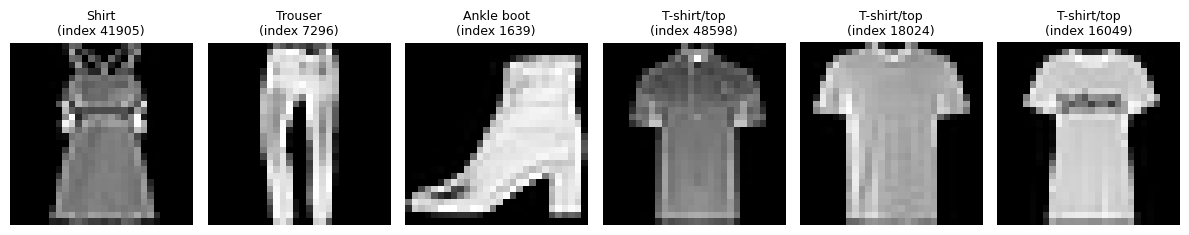

In [ ]:
# A separate random generator for this cell only, so re-running it always shows the same images
example_rng = random.Random(SEED)

# Pick 6 different positions from 0 to 59,999 (sample never goes out of range or repeats)
example_positions = example_rng.sample(range(train_data_length), 6)
print("Example positions:", example_positions)

fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))

for i, position in enumerate(example_positions):
    image, label = train_data[position]
    # squeeze() removes the colour-channel dimension: [1, 28, 28] -> [28, 28]
    axes[i].imshow(image.squeeze(), cmap='gray', interpolation='nearest')
    axes[i].set_title(f"{train_data.classes[label]}\n(index {position})", fontsize=9)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### Creating the train/validation split (training set only)

In [ ]:
# Positions 0..59,999 and the label of every training image
all_indices = list(range(train_data_length))
all_labels = train_data.targets

# Stratified split: 10,000 positions go to validation, the remaining 50,000 to training
train_indices, val_indices = train_test_split(
    all_indices,
    test_size=10000,         # size of the second group (validation, not the real test set)
    stratify=all_labels,     # keep the same class balance in both groups
    random_state=SEED,       # same split on every run
)

# Subsets only store which positions to use; no images are copied
train_set = Subset(train_data, train_indices)
val_set = Subset(train_data, val_indices)

#### Checking the split

In [ ]:
# Positions that appear in both sets (should be none)
overlap = set(train_indices) & set(val_indices)

print("Train size:            ", len(train_set))
print("Validation size:       ", len(val_set))
print("Images in both sets:   ", len(overlap))
# bincount counts how many images there are of each label 0-9
print("Train class counts:    ", torch.bincount(all_labels[train_indices]).tolist())
print("Validation class counts:", torch.bincount(all_labels[val_indices]).tolist())

Train size:             50000
Validation size:        10000
Images in both sets:    0
Train class counts:     [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]
Validation class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


Train size:             50000
Validation size:        10000
Images in both sets:    0
Train class counts:     [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]
Validation class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]

Stratified 50,000 / 10,000 split with no overlap.

### Saving the split indices

In [ ]:
# Create the folder (no error if it exists) and save both lists of positions
os.makedirs("splits", exist_ok=True)

np.save("splits/train_indices.npy", np.array(train_indices))
np.save("splits/val_indices.npy", np.array(val_indices))

### Clustering subsets (3,000 / 1,000 / 1,000)

Stratified subsets for Parts 4–5. Labels only balance them, never fit clusters.

#### Clustering training subset (3,000)

In [ ]:
# 3,000 of the 50,000 training positions, 300 per class (the other 47,000 go into _)
cluster_train_indices, _ = train_test_split(
    train_indices,
    train_size=3000,
    stratify=all_labels[train_indices],
    random_state=SEED,
)

#### Clustering validation subset (1,000)

In [ ]:
# 1,000 of the 10,000 validation positions, 100 per class
cluster_val_indices, _ = train_test_split(
    val_indices,
    train_size=1000,
    stratify=all_labels[val_indices],
    random_state=SEED,
)

#### Clustering test subset (1,000)

In [ ]:
# The test set is a separate dataset, so it needs its own positions 0..9,999
all_test_indices = list(range(test_data_length))

cluster_test_indices, _ = train_test_split(
    all_test_indices,
    train_size=1000,
    stratify=test_data.targets,
    random_state=SEED,
)

#### Checking the clustering subsets

In [ ]:
# Sizes
print("Clustering train size:     ", len(cluster_train_indices))
print("Clustering validation size:", len(cluster_val_indices))
print("Clustering test size:      ", len(cluster_test_indices))

# Images per class in each subset
print("Clustering train per class:     ", torch.bincount(all_labels[cluster_train_indices]).tolist())
print("Clustering validation per class:", torch.bincount(all_labels[cluster_val_indices]).tolist())
print("Clustering test per class:      ", torch.bincount(test_data.targets[cluster_test_indices]).tolist())

# Each subset comes from the right partition (<= means "is contained in"), and train/val do not overlap
print("Clustering train all from training partition:  ", set(cluster_train_indices) <= set(train_indices))
print("Clustering validation all from validation split:", set(cluster_val_indices) <= set(val_indices))
print("Overlap between clustering train and validation:", len(set(cluster_train_indices) & set(cluster_val_indices)))

Clustering train size:      3000
Clustering validation size: 1000
Clustering test size:       1000
Clustering train per class:      [300, 300, 300, 300, 300, 300, 300, 300, 300, 300]
Clustering validation per class: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Clustering test per class:       [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Clustering train all from training partition:   True
Clustering validation all from validation split: True
Overlap between clustering train and validation: 0


Clustering train size:      3000
Clustering validation size: 1000
Clustering test size:       1000
Clustering train per class:      [300, 300, 300, 300, 300, 300, 300, 300, 300, 300]
Clustering validation per class: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Clustering test per class:       [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Clustering train all from training partition:   True
Clustering validation all from validation split: True
Overlap between clustering train and validation: 0

Sizes and class balance are correct, with no overlap.

#### Saving the clustering subset indices

In [ ]:
# Save the three clustering subsets next to the train/validation split
np.save("splits/cluster_train_indices.npy", np.array(cluster_train_indices))
np.save("splits/cluster_val_indices.npy", np.array(cluster_val_indices))
np.save("splits/cluster_test_indices.npy", np.array(cluster_test_indices))

### DataLoaders

In [ ]:
size_of_batch = 64

# Seeded random generator for the training shuffle (_ = stops it printing an object description)
g = torch.Generator()
_ = g.manual_seed(SEED)

train_loader = DataLoader(train_set, batch_size=size_of_batch, shuffle=True, generator=g)
val_loader = DataLoader(val_set, batch_size=size_of_batch, shuffle=False)
test_loader = DataLoader(test_data, batch_size=size_of_batch, shuffle=False)

### Checking the DataLoaders

In [ ]:
# Take one batch to check its shape
temp_images, temp_labels = next(iter(train_loader))

# Reset the generator so this check does not change the training shuffle later
_ = g.manual_seed(SEED)

print("One batch of images:", tuple(temp_images.shape))
print("One batch of labels:", tuple(temp_labels.shape))
print("Train batches:      ", len(train_loader))
print("Validation batches: ", len(val_loader))
print("Test batches:       ", len(test_loader))

One batch of images: (64, 1, 28, 28)
One batch of labels: (64,)
Train batches:       782
Validation batches:  157
Test batches:        157


One batch of images: (64, 1, 28, 28)
One batch of labels: (64,)
Train batches:       782
Validation batches:  157
Test batches:        157


The generator is reset after this check, so training order is unaffected.

### Part 0 summary

| Set | Images | Per class |
|---|---|---|
| Train / validation / test | 50,000 / 10,000 / 10,000 | 5,000 / 1,000 / 1,000 |
| Clustering train / validation / test | 3,000 / 1,000 / 1,000 | 300 / 100 / 100 |

All indices are saved in `splits/`.

# Part 1: Classical classification

**Objective:** compare two classifiers, tune their complexity, analyse errors and make a cost-based decision.
1.4 runs before 1.2 and 1.3 so those use the selected settings.

## 1.1 Models

| | Logistic regression | kNN |
|---|---|---|
| Predicts | weighted sum of pixels per class, highest score wins | majority vote of the k nearest training images |
| Fitted by | L-BFGS minimising cross-entropy + L2 penalty | storing the training images |
| Complexity | C (large C = more complex) | k (small k = more complex) |

They use pixels in opposite ways, each has one complexity setting, and logistic regression gives probabilities
for 1.5. Centred, aligned images make pixel weights and distances meaningful.

### Preparing the data

In [ ]:
# Flatten each 28x28 image into one row of 784 pixels, scaled to 0-1
X_train = train_data.data[train_indices].reshape(-1, 784).numpy() / 255.0
y_train = train_data.targets[train_indices].numpy()

X_val = train_data.data[val_indices].reshape(-1, 784).numpy() / 255.0
y_val = train_data.targets[val_indices].numpy()

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_val:  ", X_val.shape, " y_val:  ", y_val.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())

X_train: (50000, 784)  y_train: (50000,)
X_val:   (10000, 784)  y_val:   (10000,)
Pixel range: 0.0 to 1.0


X_train: (50000, 784)  y_train: (50000,)
X_val:   (10000, 784)  y_val:   (10000,)
Pixel range: 0.0 to 1.0

### Logistic regression: baseline

Scaler fitted on training data only (R2).

In [ ]:
# Standardise each pixel using statistics from the TRAINING data only (R2)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learns mean and std from training data
X_val_scaled = scaler.transform(X_val)           # reuses the training mean and std

print("Train mean (approx 0):", round(X_train_scaled.mean(), 4))
print("Train std  (approx 1):", round(X_train_scaled.std(), 4))

Train mean (approx 0): 0.0
Train std  (approx 1): 1.0


In [ ]:
# Baseline: default regularisation (C = 1.0), enough iterations to converge
log_reg = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)

# Time the fit, because runtimes are part of the record
start = time.time()
log_reg.fit(X_train_scaled, y_train)
log_reg_fit_time = time.time() - start

print(f"Logistic regression training time: {log_reg_fit_time:.1f} seconds")
# If this equals max_iter, the optimiser stopped before converging
print("Iterations used:", log_reg.n_iter_)

Logistic regression training time: 291.8 seconds
Iterations used: [883]


In [ ]:
# Accuracy on the images it was trained on, and on the unseen validation images
log_reg_train_acc = accuracy_score(y_train, log_reg.predict(X_train_scaled))
log_reg_val_acc = accuracy_score(y_val, log_reg.predict(X_val_scaled))

print(f"Training accuracy:   {log_reg_train_acc:.4f}")
print(f"Validation accuracy: {log_reg_val_acc:.4f}")
# A large gap would mean overfitting
print(f"Gap (train - val):   {log_reg_train_acc - log_reg_val_acc:.4f}")

Training accuracy:   0.8879
Validation accuracy: 0.8548
Gap (train - val):   0.0331


### kNN: baseline

Unscaled pixels: scaling would magnify border noise (stated difference, R4).

In [ ]:
# Baseline kNN with k = 5; n_jobs=-1 uses all CPU cores for prediction
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

# "Fitting" kNN just stores the training images, so it is almost instant
start = time.time()
knn.fit(X_train, y_train)          # 0-1 pixels, not scaled
knn_fit_time = time.time() - start

print(f"kNN fit time: {knn_fit_time:.2f} seconds")

kNN fit time: 0.04 seconds


In [ ]:
# Prediction is the slow part: every validation image is compared with all 50,000 training images
start = time.time()
knn_val_pred = knn.predict(X_val)
knn_pred_time = time.time() - start

knn_val_acc = accuracy_score(y_val, knn_val_pred)
print(f"kNN prediction time (10,000 images): {knn_pred_time:.1f} seconds")
print(f"kNN validation accuracy: {knn_val_acc:.4f}")

kNN prediction time (10,000 images): 28.9 seconds
kNN validation accuracy: 0.8595


In [ ]:
# A fixed, seeded sample of 5,000 training rows (row numbers in X_train), reused in 1.4
sample_rng = np.random.default_rng(SEED)
train_sample = sample_rng.choice(len(X_train), size=5000, replace=False)

knn_train_acc = accuracy_score(y_train[train_sample], knn.predict(X_train[train_sample]))
print(f"kNN training accuracy (5,000-image sample): {knn_train_acc:.4f}")
print(f"Gap (train - val): {knn_train_acc - knn_val_acc:.4f}")

kNN training accuracy (5,000-image sample): 0.8978
Gap (train - val): 0.0383


| Baseline | Validation | Train − val gap | Fit time | Predict time (10k) |
|---|---|---|---|---|
| Logistic regression (C = 1) | 85.48% | 3.31 pts | 291.8 s | fast |
| kNN (k = 5) | 85.95% | 3.83 pts | 0.04 s | 28.9 s |

Similar accuracy; opposite time costs.

## 1.4 Complexity study

### kNN: varying k

In [ ]:
k_values = [1, 3, 5, 7, 11, 15, 25, 51]

knn_results = []   # one entry per k

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    model.fit(X_train, y_train)

    # Time the two prediction steps (validation + training sample)
    start = time.time()
    val_acc = accuracy_score(y_val, model.predict(X_val))
    train_acc = accuracy_score(y_train[train_sample], model.predict(X_train[train_sample]))
    elapsed = time.time() - start

    knn_results.append({"k": k, "train_acc": train_acc, "val_acc": val_acc, "time_s": elapsed})
    # {k:>2} pads the number to 2 characters so the columns line up
    print(f"k = {k:>2}:  train {train_acc:.4f}   val {val_acc:.4f}   gap {train_acc - val_acc:.4f}   ({elapsed:.0f} s)")

k =  1:  train 1.0000   val 0.8502   gap 0.1498   (43 s)
k =  3:  train 0.9206   val 0.8579   gap 0.0627   (44 s)
k =  5:  train 0.8978   val 0.8595   gap 0.0383   (43 s)
k =  7:  train 0.8888   val 0.8617   gap 0.0271   (43 s)
k = 11:  train 0.8732   val 0.8538   gap 0.0194   (52 s)
k = 15:  train 0.8650   val 0.8513   gap 0.0137   (50 s)
k = 25:  train 0.8534   val 0.8467   gap 0.0067   (44 s)
k = 51:  train 0.8358   val 0.8366   gap -0.0008   (44 s)


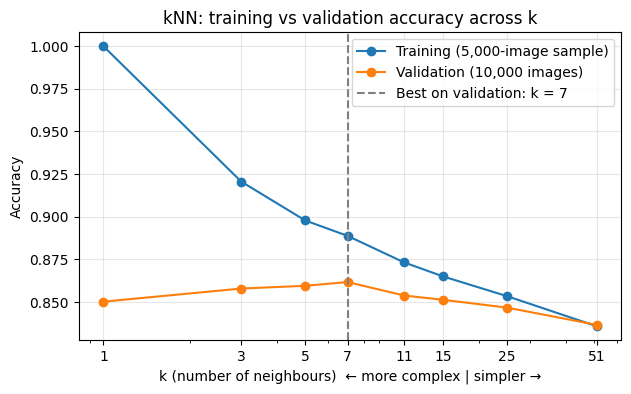

Best k on validation: 7 (validation accuracy 0.8617)


In [ ]:
# Pull each column out of the results
ks = [r["k"] for r in knn_results]
train_accs = [r["train_acc"] for r in knn_results]
val_accs = [r["val_acc"] for r in knn_results]

# Best k is chosen by code (highest validation accuracy), not typed in by hand
best = max(knn_results, key=lambda r: r["val_acc"])

plt.figure(figsize=(7, 4))
plt.plot(ks, train_accs, marker="o", label="Training (5,000-image sample)")
plt.plot(ks, val_accs, marker="o", label="Validation (10,000 images)")
plt.axvline(best["k"], linestyle="--", color="gray", label=f"Best on validation: k = {best['k']}")

# Log scale spreads out the small values of k
plt.xscale("log")
plt.xticks(ks, ks)
plt.xlabel("k (number of neighbours)  ← more complex | simpler →")
plt.ylabel("Accuracy")
plt.title("kNN: training vs validation accuracy across k")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Best k on validation: {best['k']} (validation accuracy {best['val_acc']:.4f})")

k = 1 memorises (gap 0.1498); validation peaks at **k = 7 (86.17%)** and falls for large k (83.66% at k = 51).

### Logistic regression: varying C

Swept on a 10,000-row training subset to save time.

In [ ]:
# Pick 10,000 of the 50,000 training rows, 1,000 per class
lr_subset, _ = train_test_split(
    np.arange(len(X_train)),   # row numbers in X_train
    train_size=10000,
    stratify=y_train,
    random_state=SEED,
)

X_sub = X_train_scaled[lr_subset]
y_sub = y_train[lr_subset]

print("Subset size:", len(lr_subset))
print("Per class:", np.bincount(y_sub).tolist())

Subset size: 10000
Per class: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


In [ ]:
C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
MAX_ITER = 1000

lr_results = []   # one entry per C

for C in C_values:
    model = LogisticRegression(C=C, max_iter=MAX_ITER, random_state=SEED)

    start = time.time()
    model.fit(X_sub, y_sub)
    elapsed = time.time() - start

    # Record whether the optimiser finished before hitting the iteration limit
    iters = int(model.n_iter_[0])
    converged = iters < MAX_ITER

    train_acc = accuracy_score(y_sub, model.predict(X_sub))          # the 10,000 images it was fitted on
    val_acc = accuracy_score(y_val, model.predict(X_val_scaled))     # the full validation set

    lr_results.append({"C": C, "train_acc": train_acc, "val_acc": val_acc,
                       "iters": iters, "converged": converged, "time_s": elapsed})
    print(f"C = {C:<7}  train {train_acc:.4f}   val {val_acc:.4f}   gap {train_acc - val_acc:.4f}   "
          f"iters {iters:>4} {'' if converged else '(NOT converged)'}   ({elapsed:.0f} s)")

C = 0.0001   train 0.7817   val 0.7856   gap -0.0039   iters   94    (11 s)
C = 0.001    train 0.8458   val 0.8375   gap 0.0083   iters  173    (19 s)
C = 0.01     train 0.8868   val 0.8518   gap 0.0350   iters  347    (38 s)
C = 0.1      train 0.9262   val 0.8370   gap 0.0892   iters  568    (64 s)
C = 1        train 0.9598   val 0.8083   gap 0.1515   iters  542    (60 s)
C = 10       train 0.9776   val 0.7851   gap 0.1925   iters  911    (100 s)
C = 100      train 0.9875   val 0.7725   gap 0.2150   iters 1000 (NOT converged)   (112 s)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training accuracy rises to 98.75% but validation peaks at **C = 0.01 (85.18%)**: small C underfits, large C
overfits. C = 100 did not converge.

#### Resolving the convergence warning (C = 100)

In [ ]:
# Refit C = 100 with a higher iteration limit to check whether it converges
model = LogisticRegression(C=100, max_iter=3000, random_state=SEED)
start = time.time()
model.fit(X_sub, y_sub)
print(f"Iterations: {model.n_iter_[0]}   ({time.time() - start:.0f} s)")
print(f"Train {accuracy_score(y_sub, model.predict(X_sub)):.4f}   "
      f"Val {accuracy_score(y_val, model.predict(X_val_scaled)):.4f}")

Iterations: 1510   (171 s)
Train 0.9900   Val 0.7704


With more iterations it converged (77.04%), so the drop is overfitting.

#### Plot of the C sweep

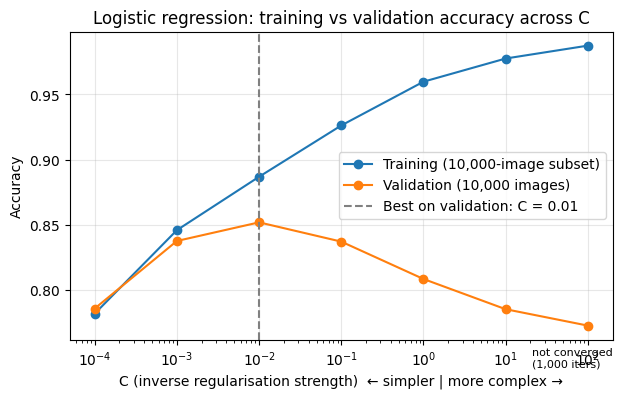

In [ ]:
# Pull each column out of the results
Cs = [r["C"] for r in lr_results]
lr_train = [r["train_acc"] for r in lr_results]
lr_val = [r["val_acc"] for r in lr_results]
best_sub = max(lr_results, key=lambda r: r["val_acc"])

plt.figure(figsize=(7, 4))
plt.plot(Cs, lr_train, marker="o", label="Training (10,000-image subset)")
plt.plot(Cs, lr_val, marker="o", label="Validation (10,000 images)")
plt.axvline(best_sub["C"], linestyle="--", color="gray", label=f"Best on validation: C = {best_sub['C']}")

# Label any fit that hit the iteration limit
for r in lr_results:
    if not r["converged"]:
        plt.annotate("not converged\n(1,000 iters)", (r["C"], r["val_acc"]),
                     textcoords="offset points", xytext=(-40, -30), fontsize=8)

plt.xscale("log")
plt.xlabel("C (inverse regularisation strength)  ← simpler | more complex →")
plt.ylabel("Accuracy")
plt.title("Logistic regression: training vs validation accuracy across C")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Choosing C on the full training set

In [ ]:
# Validation accuracy for each candidate C, trained on all 50,000 images
full_results = {1.0: log_reg_val_acc}   # C = 1 is the baseline fitted earlier

for C in [0.01, 0.1]:
    model = LogisticRegression(C=C, max_iter=MAX_ITER, random_state=SEED)
    start = time.time()
    model.fit(X_train_scaled, y_train)
    elapsed = time.time() - start
    val_acc = accuracy_score(y_val, model.predict(X_val_scaled))
    full_results[C] = val_acc
    print(f"C = {C:<5}  val {val_acc:.4f}   iters {model.n_iter_[0]}   ({elapsed:.0f} s)")

# The C with the highest validation accuracy
best_C = max(full_results, key=full_results.get)
print(f"\nBest C on full training set: {best_C} (val {full_results[best_C]:.4f})")

C = 0.01   val 0.8640   iters 473   (155 s)
C = 0.1    val 0.8613   iters 760   (248 s)

Best C on full training set: 0.01 (val 0.8640)


C = 0.01 is best on full data too (86.40%).

### Final selected models

The selected settings are refitted under clear names, so that 1.2, 1.3 and 1.5 use exactly these models.

In [ ]:
# Final logistic regression with the C selected on validation
final_log_reg = LogisticRegression(C=best_C, max_iter=MAX_ITER, random_state=SEED)

start = time.time()
final_log_reg.fit(X_train_scaled, y_train)
print(f"Fit time: {time.time() - start:.0f} s   iterations: {final_log_reg.n_iter_[0]}")

final_lr_train_acc = accuracy_score(y_train, final_log_reg.predict(X_train_scaled))
final_lr_val_acc = accuracy_score(y_val, final_log_reg.predict(X_val_scaled))
print(f"Final logistic regression (C = {best_C}): train {final_lr_train_acc:.4f}   val {final_lr_val_acc:.4f}")

Fit time: 155 s   iterations: 473
Final logistic regression (C = 0.01): train 0.8750   val 0.8640


In [ ]:
# Final kNN with the k selected on validation (taken from the sweep, not typed in)
best_k = best["k"]
final_knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
final_knn.fit(X_train, y_train)
print(f"Final kNN: k = {best_k}")

Final kNN: k = 7


Gap 1.10 points, down from 3.31 at C = 1.

## 1.2 Metrics

In [ ]:
# Class names instead of 0-9 in all reports
class_names = train_data.classes

# Predictions from the final models (saved so 1.3 can reuse them without waiting again)
lr_val_pred = final_log_reg.predict(X_val_scaled)
knn_val_pred = final_knn.predict(X_val)          # about a minute

print(f"Validation accuracy, logistic regression (C = {best_C}): {accuracy_score(y_val, lr_val_pred):.4f}")
print(f"Validation accuracy, kNN (k = {best_k}):                  {accuracy_score(y_val, knn_val_pred):.4f}")

Validation accuracy, logistic regression (C = 0.01): 0.8640
Validation accuracy, kNN (k = 7):                  0.8617


In [ ]:
# Precision, recall, F1 and support for every class
print(f"Logistic regression (C = {best_C}), validation set\n")
print(classification_report(y_val, lr_val_pred, target_names=class_names, digits=3))

print(f"\nkNN (k = {best_k}), validation set\n")
print(classification_report(y_val, knn_val_pred, target_names=class_names, digits=3))

Logistic regression (C = 0.01), validation set

              precision    recall  f1-score   support

 T-shirt/top      0.805     0.851     0.827      1000
     Trouser      0.981     0.969     0.975      1000
    Pullover      0.766     0.768     0.767      1000
       Dress      0.860     0.872     0.866      1000
        Coat      0.767     0.785     0.776      1000
      Sandal      0.936     0.943     0.939      1000
       Shirt      0.681     0.622     0.650      1000
     Sneaker      0.926     0.928     0.927      1000
         Bag      0.957     0.952     0.954      1000
  Ankle boot      0.953     0.950     0.951      1000

    accuracy                          0.864     10000
   macro avg      0.863     0.864     0.863     10000
weighted avg      0.863     0.864     0.863     10000


kNN (k = 7), validation set

              precision    recall  f1-score   support

 T-shirt/top      0.792     0.900     0.842      1000
     Trouser      0.991     0.964     0.977      1000


Trouser, Bag and Ankle boot are easiest (F1 > 0.93); **Shirt** is hardest (recall 0.622 for both).

In [ ]:
# The same reports as dictionaries, so single numbers can be picked out
lr_report = classification_report(y_val, lr_val_pred, target_names=class_names, output_dict=True)
knn_report = classification_report(y_val, knn_val_pred, target_names=class_names, output_dict=True)

# Recall for each class, side by side
print(f"{'Class':<12} {'Support':>7}  {'LogReg recall':>13}  {'kNN recall':>10}")
for name in class_names:
    print(f"{name:<12} {lr_report[name]['support']:>7.0f}  "
          f"{lr_report[name]['recall']:>13.3f}  {knn_report[name]['recall']:>10.3f}")

Class        Support  LogReg recall  kNN recall
T-shirt/top     1000          0.851       0.900
Trouser         1000          0.969       0.964
Pullover        1000          0.768       0.808
Dress           1000          0.872       0.857
Coat            1000          0.785       0.755
Sandal          1000          0.943       0.828
Shirt           1000          0.622       0.622
Sneaker         1000          0.928       0.957
Bag             1000          0.952       0.954
Ankle boot      1000          0.950       0.972


kNN misses more sandals (recall 0.828 vs 0.943).

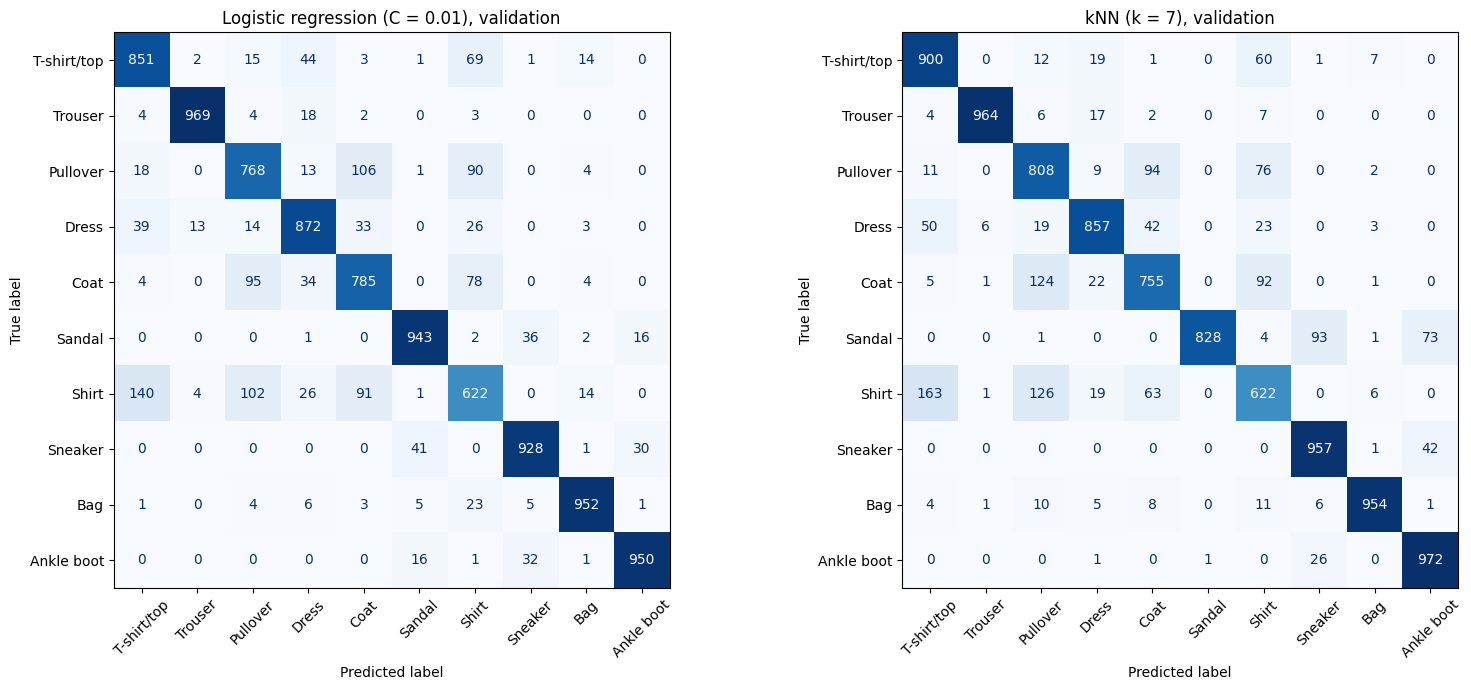

In [ ]:
# Rows = true class, columns = predicted class; the diagonal holds correct predictions
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ConfusionMatrixDisplay.from_predictions(
    y_val, lr_val_pred, display_labels=class_names,
    xticks_rotation=45, cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"Logistic regression (C = {best_C}), validation")

ConfusionMatrixDisplay.from_predictions(
    y_val, knn_val_pred, display_labels=class_names,
    xticks_rotation=45, cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title(f"kNN (k = {best_k}), validation")

plt.tight_layout()
plt.show()

Errors stay within shape groups: shirts become T-shirts (140 / 163); kNN sends sandals to Sneaker (93).

## 1.3 Error analysis

Every validation image is sorted into four groups depending on which model classified it correctly. A seeded
sample from each group is then inspected, with **both models' predictions on the same images**.

In [ ]:
# True/False for each of the 10,000 validation images
lr_correct = (lr_val_pred == y_val)
knn_correct = (knn_val_pred == y_val)

# & means "and", ~ means "not"; np.where(...)[0] gives the matching row numbers in X_val
groups = {
    "Both correct":        np.where(lr_correct & knn_correct)[0],
    "Both wrong":          np.where(~lr_correct & ~knn_correct)[0],
    "Only LogReg correct": np.where(lr_correct & ~knn_correct)[0],
    "Only kNN correct":    np.where(~lr_correct & knn_correct)[0],
}

for name, rows in groups.items():
    print(f"{name:<20} {len(rows):>5} images")

Both correct          8045 images
Both wrong             788 images
Only LogReg correct    595 images
Only kNN correct       572 images


They disagree on 1,167 images: about 42% of each model's errors are its own.

Both correct: X_val rows [4349, 901, 6530, 7745] (original indices [52500, 2662, 16347, 37936])
Both wrong: X_val rows [6995, 2127, 957, 5561] (original indices [46736, 11613, 13868, 45198])
Only LogReg correct: X_val rows [7125, 5118, 7699, 1392] (original indices [39088, 35108, 20124, 3889])
Only kNN correct: X_val rows [3717, 7755, 1786, 9098] (original indices [24237, 46750, 45674, 5086])


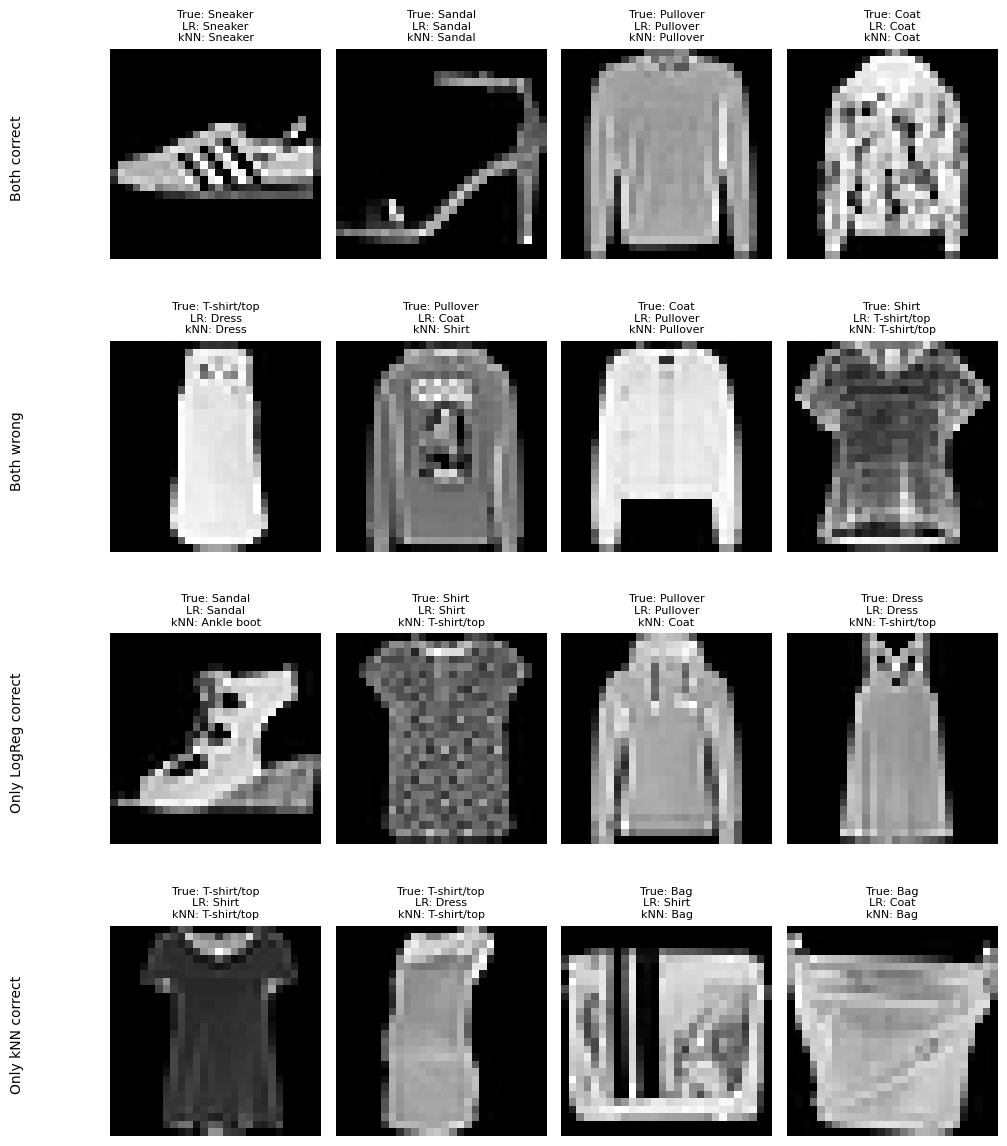

In [ ]:
# Seeded generator, so the same 16 images are shown on every run
rng_errors = np.random.default_rng(SEED)
n_per_group = 4

fig, axes = plt.subplots(4, n_per_group, figsize=(10, 12))

for row, (group_name, rows) in enumerate(groups.items()):
    # 4 different images from this group
    chosen = rng_errors.choice(rows, size=n_per_group, replace=False)
    # Record both index types: row in X_val and position in the original 60,000 images
    print(f"{group_name}: X_val rows {chosen.tolist()} "
          f"(original indices {[val_indices[i] for i in chosen]})")

    for col, i in enumerate(chosen):
        ax = axes[row, col]
        ax.imshow(X_val[i].reshape(28, 28), cmap="gray", interpolation="nearest")
        ax.set_title(f"True: {class_names[y_val[i]]}\n"
                     f"LR: {class_names[lr_val_pred[i]]}\n"
                     f"kNN: {class_names[knn_val_pred[i]]}", fontsize=8)
        ax.axis("off")

    # Group name down the left-hand side of each row
    axes[row, 0].text(-12, 14, group_name, rotation=90, va="center", ha="right", fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
# For each class: how many of its 1,000 validation images neither model gets right
print(f"{'Class':<12} {'Both wrong':>10}  (out of 1,000)")
for c, name in enumerate(class_names):
    both_wrong = np.sum((y_val == c) & ~lr_correct & ~knn_correct)
    print(f"{name:<12} {both_wrong:>10}")

Class        Both wrong  (out of 1,000)
T-shirt/top          65
Trouser              25
Pullover            120
Dress                84
Coat                133
Sandal               48
Shirt               248
Sneaker              20
Bag                  26
Ankle boot           19


Tops cause 650 of 788 shared errors; Shirt alone 248.

## 1.5 Decisions and costs: Shirt vs not Shirt

Flagged shirts go to an ironing station. A missed shirt is resold creased; a false alarm costs seconds. Cost =
5 × FN + 1 × FP (assumed; other ratios tested).

In [ ]:
SHIRT = class_names.index("Shirt")      # the label number for Shirt (6)

# predict_proba gives 10 probabilities per image; keep the "Shirt" column (found safely, not assumed)
shirt_col = list(final_log_reg.classes_).index(SHIRT)
val_shirt_proba = final_log_reg.predict_proba(X_val_scaled)[:, shirt_col]

y_val_shirt = (y_val == SHIRT).astype(int)   # 1 = Shirt, 0 = not Shirt

print("Shirt label number:", SHIRT)
print("Validation shirts:    ", y_val_shirt.sum())
print("Validation non-shirts:", (y_val_shirt == 0).sum())
print("Example probabilities:", np.round(val_shirt_proba[:5], 3))

Shirt label number: 6
Validation shirts:     1000
Validation non-shirts: 9000
Example probabilities: [0.002 0.001 0.183 0.    0.575]


In [ ]:
COST_FN = 5   # a missed shirt: resold creased, likely complaint or return
COST_FP = 1   # a non-shirt sent to the shirt station: a worker moves it back

thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)   # 0.05, 0.10, ..., 0.95
threshold_results = []

for t in thresholds:
    # Flag as Shirt if P(Shirt) is at least t
    pred = (val_shirt_proba >= t).astype(int)

    tp = np.sum((pred == 1) & (y_val_shirt == 1))   # shirts correctly flagged
    fp = np.sum((pred == 1) & (y_val_shirt == 0))   # non-shirts wrongly flagged
    fn = np.sum((pred == 0) & (y_val_shirt == 1))   # shirts missed
    tn = np.sum((pred == 0) & (y_val_shirt == 0))   # non-shirts correctly passed

    # The if/else avoids dividing by zero when nothing is flagged
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn)
    cost = COST_FN * fn + COST_FP * fp

    threshold_results.append({"t": t, "tp": tp, "fp": fp, "fn": fn, "tn": tn,
                              "precision": precision, "recall": recall, "cost": cost})

print(f"{'Thresh':>6} {'TP':>5} {'FP':>5} {'FN':>5} {'Prec':>6} {'Recall':>6} {'Cost':>6}")
for r in threshold_results:
    print(f"{r['t']:>6.2f} {r['tp']:>5} {r['fp']:>5} {r['fn']:>5} "
          f"{r['precision']:>6.3f} {r['recall']:>6.3f} {r['cost']:>6}")

Thresh    TP    FP    FN   Prec Recall   Cost
  0.05   960  2000    40  0.324  0.960   2200
  0.10   910  1340    90  0.404  0.910   1790
  0.15   860  1013   140  0.459  0.860   1713
  0.20   815   782   185  0.510  0.815   1707
  0.25   765   604   235  0.559  0.765   1779
  0.30   720   472   280  0.604  0.720   1872
  0.35   677   384   323  0.638  0.677   1999
  0.40   637   312   363  0.671  0.637   2127
  0.45   598   239   402  0.714  0.598   2249
  0.50   549   189   451  0.744  0.549   2444
  0.55   509   144   491  0.779  0.509   2599
  0.60   466   120   534  0.795  0.466   2790
  0.65   420    88   580  0.827  0.420   2988
  0.70   368    66   632  0.848  0.368   3226
  0.75   294    47   706  0.862  0.294   3577
  0.80   219    33   781  0.869  0.219   3938
  0.85   158    19   842  0.893  0.158   4229
  0.90    85     9   915  0.904  0.085   4584
  0.95    33     2   967  0.943  0.033   4837


Higher thresholds trade false positives for false negatives.

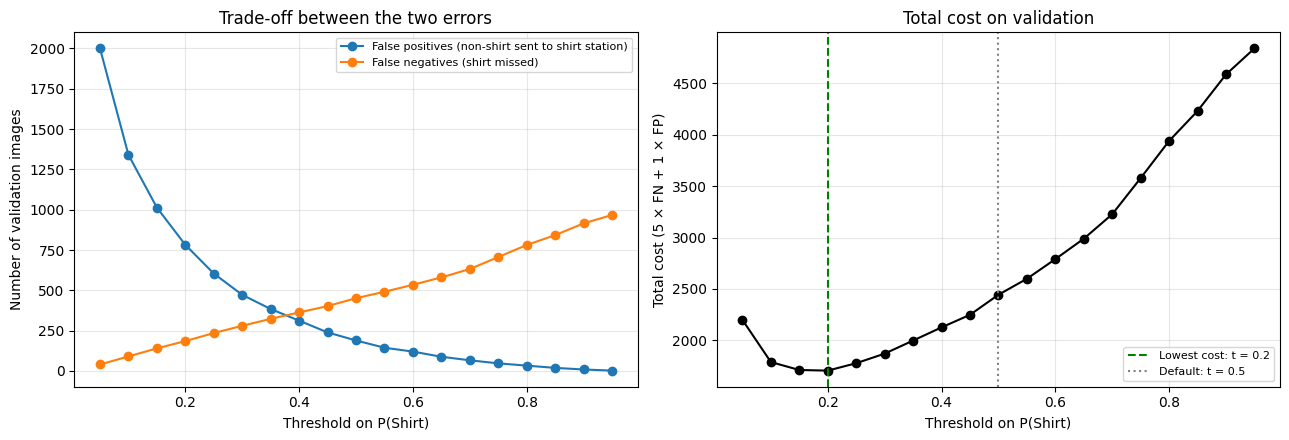

Chosen threshold: 0.2  cost 1707  (FN 185, FP 782, recall 0.815, precision 0.510)
Default 0.5:      cost 2444  (FN 451, FP 189, recall 0.549, precision 0.744)


In [ ]:
# Columns for plotting
ts = [r["t"] for r in threshold_results]
fps = [r["fp"] for r in threshold_results]
fns = [r["fn"] for r in threshold_results]
costs = [r["cost"] for r in threshold_results]

# Lowest-cost threshold (chosen by code) and the default 0.5 for comparison
best_t = min(threshold_results, key=lambda r: r["cost"])
default = next(r for r in threshold_results if r["t"] == 0.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: how the two errors trade off
axes[0].plot(ts, fps, marker="o", label="False positives (non-shirt sent to shirt station)")
axes[0].plot(ts, fns, marker="o", label="False negatives (shirt missed)")
axes[0].set_xlabel("Threshold on P(Shirt)")
axes[0].set_ylabel("Number of validation images")
axes[0].set_title("Trade-off between the two errors")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Right: total cost, with the chosen operating point and the default
axes[1].plot(ts, costs, marker="o", color="black")
axes[1].axvline(best_t["t"], linestyle="--", color="green", label=f"Lowest cost: t = {best_t['t']}")
axes[1].axvline(0.5, linestyle=":", color="gray", label="Default: t = 0.5")
axes[1].set_xlabel("Threshold on P(Shirt)")
axes[1].set_ylabel(f"Total cost ({COST_FN} × FN + {COST_FP} × FP)")
axes[1].set_title("Total cost on validation")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Chosen threshold: {best_t['t']}  cost {best_t['cost']}  "
      f"(FN {best_t['fn']}, FP {best_t['fp']}, recall {best_t['recall']:.3f}, precision {best_t['precision']:.3f})")
print(f"Default 0.5:      cost {default['cost']}  "
      f"(FN {default['fn']}, FP {default['fp']}, recall {default['recall']:.3f}, precision {default['precision']:.3f})")

**t = 0.20** costs 1,707 versus 2,444 at t = 0.5.

In [ ]:
# Best threshold for different FN:FP cost ratios (FP cost fixed at 1)
print(f"{'FN:FP cost ratio':>16} {'Best threshold':>15} {'FN':>5} {'FP':>5}")
for ratio in [1, 2, 5, 10, 20]:
    # Named best_for_ratio so it does not overwrite `best` (the kNN sweep result)
    best_for_ratio = min(threshold_results, key=lambda r: ratio * r["fn"] + 1 * r["fp"])
    print(f"{ratio:>13}:1 {best_for_ratio['t']:>15.2f} {best_for_ratio['fn']:>5} {best_for_ratio['fp']:>5}")

FN:FP cost ratio  Best threshold    FN    FP
            1:1            0.55   491   144
            2:1            0.35   323   384
            5:1            0.20   185   782
           10:1            0.10    90  1340
           20:1            0.05    40  2000


The best threshold falls as misses cost more, close to C_FP / (C_FP + C_FN).

## Part 1 summary

| | Logistic regression (C = 0.01) | kNN (k = 7) |
|---|---|---|
| Validation accuracy | 86.40% | 86.17% |
| Train − val gap | 1.10 pts | 2.71 pts |
| Predict time (10k) | fast | about 29 s |
| Gives probabilities | yes | no |

Tied accuracy; logistic regression is more practical. Both struggle with Shirt.

# Part 2: Neural networks: architecture and learning

**Objective:** train an MLP from scratch, then change only its size (2.2) and only its learning rate (2.3).

| Recipe | Value |
|---|---|
| Architecture | 784 → 256 → 128 → 10, ReLU |
| Loss / optimiser | cross-entropy / hand-written SGD, lr 0.1, batch 64, 20 epochs |
| Checkpoint | epoch with the highest validation accuracy |
| Initialisation | PyTorch default after `torch.manual_seed(42)` |

## 2.1 Baseline MLP

In [ ]:
class MLP(nn.Module):
    """A feed-forward network: flatten -> hidden layers with ReLU -> 10 class scores."""

    def __init__(self, hidden_sizes):
        super().__init__()
        layers = []
        in_size = 784                               # 28 x 28 pixels
        for h in hidden_sizes:
            layers.append(nn.Linear(in_size, h))    # weights and biases
            layers.append(nn.ReLU())                # non-linearity
            in_size = h
        layers.append(nn.Linear(in_size, 10))       # one score per class (no softmax here)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)                   # [batch, 1, 28, 28] -> [batch, 784]
        return self.net(x)


def count_parameters(model):
    """Number of trainable weights and biases."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


BASELINE_HIDDEN = [256, 128]

torch.manual_seed(SEED)                             # fixes the initial weights
baseline_model = MLP(BASELINE_HIDDEN).to(device)

print(baseline_model)
print("Trainable parameters:", count_parameters(baseline_model))

MLP(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 235146


The output confirms the layer list and **235,146 trainable parameters**:
784 × 256 + 256 = 200,960; 256 × 128 + 128 = 32,896; 128 × 10 + 10 = 1,290.

235,146 trainable parameters; the highest of 10 scores is the prediction.

### Loss, training loop and validation loop

`loss.backward()` computes gradients; `p -= lr * p.grad` updates each weight.

In [ ]:
loss_fn = nn.CrossEntropyLoss()      # softmax + negative log-likelihood, averaged over the batch


def train_one_epoch(model, loader, lr):
    """One pass over the training data, updating the weights after every batch (plain SGD)."""
    model.train()
    total_loss, correct, n = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        # 1. Forward pass: compute class scores and the loss
        logits = model(images)
        loss = loss_fn(logits, labels)

        # 2. Backward pass: autodiff computes d(loss)/d(parameter) for every weight and bias
        model.zero_grad()            # clear gradients from the previous batch
        loss.backward()

        # 3. Gradient update (plain SGD): move each parameter a small step against its gradient
        with torch.no_grad():
            for p in model.parameters():
                p -= lr * p.grad

        # Keep running totals for this epoch
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        n += labels.size(0)

    return total_loss / n, correct / n


def evaluate(model, loader):
    """Loss and accuracy on a dataset, without changing the weights."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0

    with torch.no_grad():            # no gradients needed for evaluation
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            total_loss += loss_fn(logits, labels).item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            n += labels.size(0)

    return total_loss / n, correct / n

### Full training run with the checkpoint rule

In [ ]:
def train_model(hidden_sizes, lr=0.1, epochs=20, seed=SEED, name="model"):
    """Train an MLP from scratch and keep the epoch with the best validation accuracy."""
    torch.manual_seed(seed)                  # same initial weights for the same seed
    _ = g.manual_seed(seed)                  # same training shuffle order for every run (R4)
    model = MLP(hidden_sizes).to(device)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_epoch, best_state = -1.0, 0, None
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, lr)
        val_loss, val_acc = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # Checkpoint rule: keep a copy of the weights with the best validation accuracy so far
        if val_acc > best_val_acc:
            best_val_acc, best_epoch = val_acc, epoch
            best_state = copy.deepcopy(model.state_dict())

        print(f"{name} | epoch {epoch:>2}: train loss {train_loss:.4f} acc {train_acc:.4f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    elapsed = time.time() - start
    model.load_state_dict(best_state)        # restore the best checkpoint

    os.makedirs("checkpoints", exist_ok=True)
    torch.save(best_state, f"checkpoints/{name}.pt")

    summary = {"name": name, "hidden": hidden_sizes, "lr": lr, "params": count_parameters(model),
               "best_epoch": best_epoch, "best_val_acc": best_val_acc,
               "final_train_loss": history["train_loss"][-1], "time_s": elapsed}
    print(f"\n{name}: best val acc {best_val_acc:.4f} at epoch {best_epoch}, "
          f"{summary['params']:,} parameters, {elapsed:.0f} s")
    return model, history, summary

### Training the baseline

In [ ]:
baseline_model, baseline_hist, baseline_summary = train_model(BASELINE_HIDDEN, lr=0.1, epochs=20, name="baseline")

baseline | epoch  1: train loss 0.7278 acc 0.7408 | val loss 0.6490 acc 0.7691
baseline | epoch  2: train loss 0.4550 acc 0.8352 | val loss 0.5814 acc 0.7826
baseline | epoch  3: train loss 0.3999 acc 0.8535 | val loss 0.4468 acc 0.8332
baseline | epoch  4: train loss 0.3706 acc 0.8635 | val loss 0.4458 acc 0.8370
baseline | epoch  5: train loss 0.3467 acc 0.8725 | val loss 0.4282 acc 0.8470
baseline | epoch  6: train loss 0.3297 acc 0.8775 | val loss 0.4806 acc 0.8248
baseline | epoch  7: train loss 0.3141 acc 0.8845 | val loss 0.3775 acc 0.8571
baseline | epoch  8: train loss 0.3016 acc 0.8874 | val loss 0.4654 acc 0.8247
baseline | epoch  9: train loss 0.2902 acc 0.8925 | val loss 0.3375 acc 0.8793
baseline | epoch 10: train loss 0.2805 acc 0.8946 | val loss 0.3448 acc 0.8723
baseline | epoch 11: train loss 0.2716 acc 0.8986 | val loss 0.3173 acc 0.8836
baseline | epoch 12: train loss 0.2615 acc 0.9012 | val loss 0.2997 acc 0.8893
baseline | epoch 13: train loss 0.2542 acc 0.9047 | 

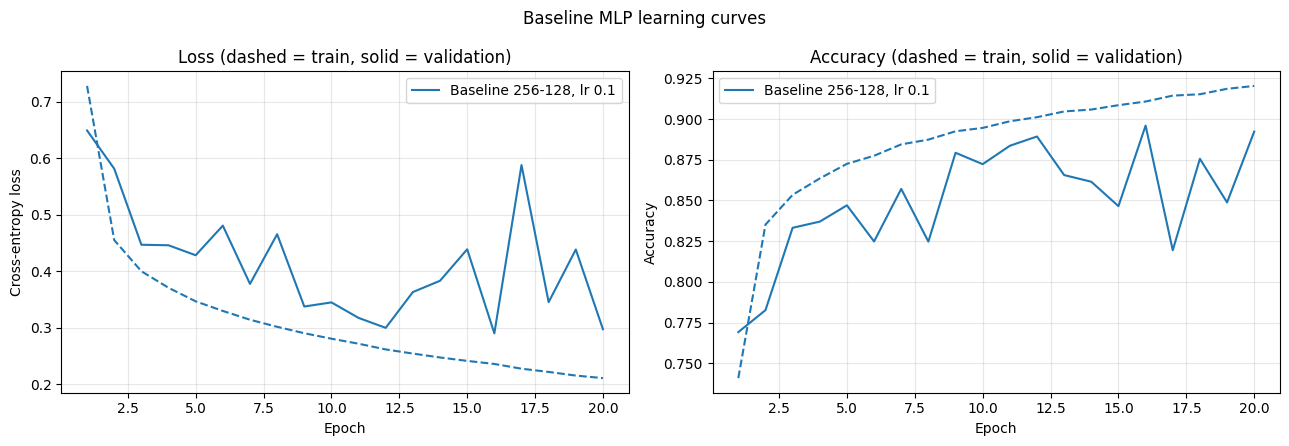

In [ ]:
def plot_curves(histories, title):
    """Loss and accuracy per epoch; dashed = training, solid = validation."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for label, h in histories.items():
        epochs = range(1, len(h["train_loss"]) + 1)
        line, = axes[0].plot(epochs, h["train_loss"], linestyle="--")
        axes[0].plot(epochs, h["val_loss"], color=line.get_color(), label=label)
        axes[1].plot(epochs, h["train_acc"], linestyle="--", color=line.get_color())
        axes[1].plot(epochs, h["val_acc"], color=line.get_color(), label=label)

    axes[0].set_title("Loss (dashed = train, solid = validation)")
    axes[1].set_title("Accuracy (dashed = train, solid = validation)")
    for ax, ylabel in zip(axes, ["Cross-entropy loss", "Accuracy"]):
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_curves({"Baseline 256-128, lr 0.1": baseline_hist}, "Baseline MLP learning curves")

Training loss fell steadily (0.7278 → 0.2108) but validation was noisy (81.94% at epoch 17) because SGD steps are
large. The best checkpoint (**89.60%**) beats Part 1, though it is slightly optimistic.

## 2.2 Experiment A: capacity

In [ ]:
# Same recipe as the baseline; only the hidden layers change
small_model, small_hist, small_summary = train_model([32], lr=0.1, epochs=20, name="small")

small | epoch  1: train loss 0.6924 acc 0.7544 | val loss 0.6997 acc 0.7460
small | epoch  2: train loss 0.4782 acc 0.8301 | val loss 0.4736 acc 0.8299
small | epoch  3: train loss 0.4306 acc 0.8466 | val loss 0.5111 acc 0.7980
small | epoch  4: train loss 0.4069 acc 0.8530 | val loss 0.4730 acc 0.8260
small | epoch  5: train loss 0.3873 acc 0.8603 | val loss 0.4469 acc 0.8376
small | epoch  6: train loss 0.3728 acc 0.8643 | val loss 0.4302 acc 0.8424
small | epoch  7: train loss 0.3602 acc 0.8694 | val loss 0.4808 acc 0.8090
small | epoch  8: train loss 0.3519 acc 0.8726 | val loss 0.4824 acc 0.8201
small | epoch  9: train loss 0.3426 acc 0.8743 | val loss 0.3608 acc 0.8702
small | epoch 10: train loss 0.3352 acc 0.8777 | val loss 0.3616 acc 0.8680
small | epoch 11: train loss 0.3287 acc 0.8804 | val loss 0.3586 acc 0.8711
small | epoch 12: train loss 0.3230 acc 0.8813 | val loss 0.3427 acc 0.8746
small | epoch 13: train loss 0.3165 acc 0.8838 | val loss 0.5102 acc 0.8306
small | epoc

In [ ]:
# Same recipe as the baseline; only the hidden layers change
large_model, large_hist, large_summary = train_model([1024, 512], lr=0.1, epochs=20, name="large")

large | epoch  1: train loss 0.6791 acc 0.7605 | val loss 0.6196 acc 0.7811
large | epoch  2: train loss 0.4383 acc 0.8408 | val loss 0.5765 acc 0.7866
large | epoch  3: train loss 0.3868 acc 0.8586 | val loss 0.4210 acc 0.8415
large | epoch  4: train loss 0.3577 acc 0.8676 | val loss 0.4432 acc 0.8370
large | epoch  5: train loss 0.3335 acc 0.8773 | val loss 0.4178 acc 0.8514
large | epoch  6: train loss 0.3161 acc 0.8816 | val loss 0.4225 acc 0.8423
large | epoch  7: train loss 0.3001 acc 0.8884 | val loss 0.3645 acc 0.8638
large | epoch  8: train loss 0.2861 acc 0.8938 | val loss 0.4281 acc 0.8382
large | epoch  9: train loss 0.2745 acc 0.8979 | val loss 0.3663 acc 0.8712
large | epoch 10: train loss 0.2646 acc 0.9011 | val loss 0.3217 acc 0.8817
large | epoch 11: train loss 0.2541 acc 0.9053 | val loss 0.3161 acc 0.8869
large | epoch 12: train loss 0.2443 acc 0.9081 | val loss 0.2998 acc 0.8903
large | epoch 13: train loss 0.2358 acc 0.9113 | val loss 0.3689 acc 0.8688
large | epoc

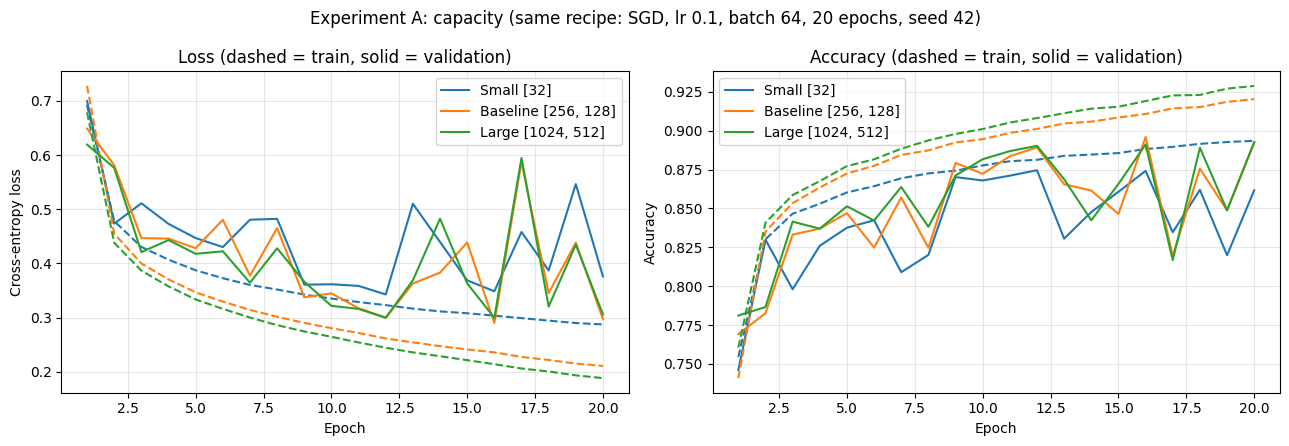

Model      Hidden           Params  Best val  Epoch  Final train loss  Time (s)
small      [32]             25,450    0.8746     12            0.2874       146
baseline   [256, 128]      235,146    0.8960     16            0.2108       172
large      [1024, 512]   1,333,770    0.8928     20            0.1883       321


In [ ]:
plot_curves({"Small [32]": small_hist,
             "Baseline [256, 128]": baseline_hist,
             "Large [1024, 512]": large_hist},
            "Experiment A: capacity (same recipe: SGD, lr 0.1, batch 64, 20 epochs, seed 42)")

print(f"{'Model':<10} {'Hidden':<12} {'Params':>10} {'Best val':>9} {'Epoch':>6} "
      f"{'Final train loss':>17} {'Time (s)':>9}")
for s in [small_summary, baseline_summary, large_summary]:
    print(f"{s['name']:<10} {str(s['hidden']):<12} {s['params']:>10,} {s['best_val_acc']:>9.4f} "
          f"{s['best_epoch']:>6} {s['final_train_loss']:>17.4f} {s['time_s']:>9.0f}")

| Model | Parameters | Best val (epoch) | Final train loss | Time |
|---|---|---|---|---|
| Small [32] | 25,450 | 87.46% (12) | 0.2874 | 146 s |
| Baseline [256, 128] | 235,146 | 89.60% (16) | 0.2108 | 172 s |
| Large [1024, 512] | 1,333,770 | 89.28% (20) | 0.1883 | 321 s |

More capacity improved training fit but not validation beyond the baseline. The small model plateaued (capacity);
the large one was still improving at epoch 20 (optimisation budget).

## 2.3 Experiment B: learning rate

The learning rate sets the step size; settings 0.01, 0.1 and 0.5.

In [ ]:
# Baseline architecture and recipe; only the learning rate changes
lr001_model, lr001_hist, lr001_summary = train_model(BASELINE_HIDDEN, lr=0.01, epochs=20, name="lr_0.01")

lr_0.01 | epoch  1: train loss 1.5260 acc 0.5285 | val loss 0.9050 acc 0.6806
lr_0.01 | epoch  2: train loss 0.7801 acc 0.7082 | val loss 0.6896 acc 0.7519
lr_0.01 | epoch  3: train loss 0.6468 acc 0.7727 | val loss 0.6054 acc 0.7836
lr_0.01 | epoch  4: train loss 0.5749 acc 0.8014 | val loss 0.5437 acc 0.8061
lr_0.01 | epoch  5: train loss 0.5313 acc 0.8161 | val loss 0.5016 acc 0.8231
lr_0.01 | epoch  6: train loss 0.5026 acc 0.8244 | val loss 0.5045 acc 0.8191
lr_0.01 | epoch  7: train loss 0.4822 acc 0.8321 | val loss 0.4938 acc 0.8238
lr_0.01 | epoch  8: train loss 0.4680 acc 0.8362 | val loss 0.4835 acc 0.8241
lr_0.01 | epoch  9: train loss 0.4546 acc 0.8410 | val loss 0.4264 acc 0.8523
lr_0.01 | epoch 10: train loss 0.4444 acc 0.8442 | val loss 0.4240 acc 0.8516
lr_0.01 | epoch 11: train loss 0.4364 acc 0.8476 | val loss 0.4129 acc 0.8579
lr_0.01 | epoch 12: train loss 0.4278 acc 0.8511 | val loss 0.4178 acc 0.8525
lr_0.01 | epoch 13: train loss 0.4198 acc 0.8536 | val loss 0.44

In [ ]:
# Baseline architecture and recipe; only the learning rate changes
lr05_model, lr05_hist, lr05_summary = train_model(BASELINE_HIDDEN, lr=0.5, epochs=20, name="lr_0.5")

lr_0.5 | epoch  1: train loss 0.7482 acc 0.7157 | val loss 0.6735 acc 0.7709
lr_0.5 | epoch  2: train loss 0.4643 acc 0.8261 | val loss 0.6379 acc 0.7693
lr_0.5 | epoch  3: train loss 0.4053 acc 0.8507 | val loss 0.4305 acc 0.8498
lr_0.5 | epoch  4: train loss 0.3722 acc 0.8612 | val loss 0.5751 acc 0.7833
lr_0.5 | epoch  5: train loss 0.3507 acc 0.8690 | val loss 0.3835 acc 0.8651
lr_0.5 | epoch  6: train loss 0.3339 acc 0.8744 | val loss 0.5579 acc 0.8094
lr_0.5 | epoch  7: train loss 0.3200 acc 0.8796 | val loss 0.3649 acc 0.8739
lr_0.5 | epoch  8: train loss 0.3109 acc 0.8843 | val loss 0.5030 acc 0.8289
lr_0.5 | epoch  9: train loss 0.3011 acc 0.8864 | val loss 0.5858 acc 0.7926
lr_0.5 | epoch 10: train loss 0.2898 acc 0.8915 | val loss 0.3642 acc 0.8692
lr_0.5 | epoch 11: train loss 0.2828 acc 0.8945 | val loss 0.3538 acc 0.8741
lr_0.5 | epoch 12: train loss 0.2741 acc 0.8963 | val loss 0.3365 acc 0.8797
lr_0.5 | epoch 13: train loss 0.2670 acc 0.8992 | val loss 0.4131 acc 0.8687

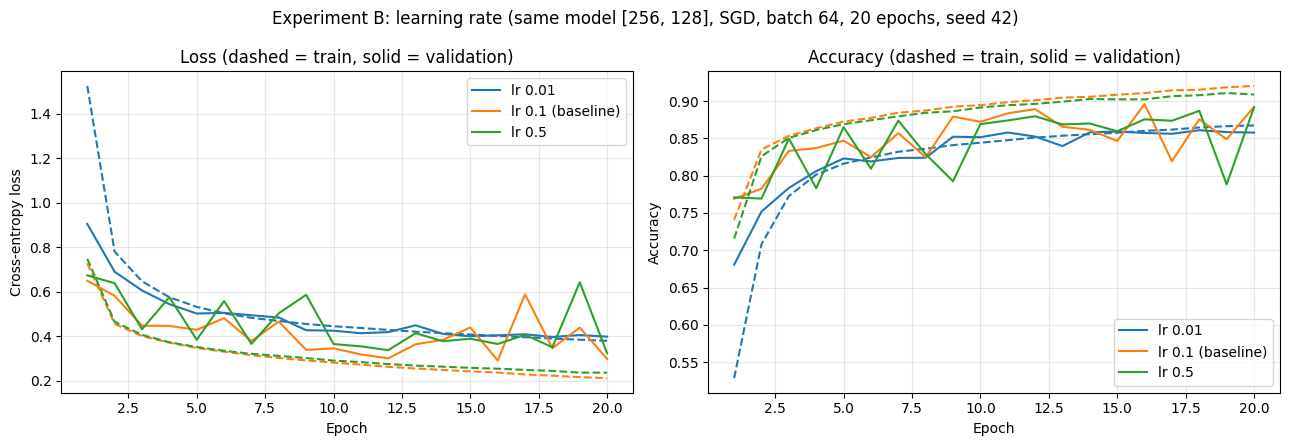

Run           lr  Best val  Epoch  Final train loss  Time (s)
lr_0.01     0.01    0.8610     18            0.3786       172
baseline     0.1    0.8960     16            0.2108       172
lr_0.5       0.5    0.8915     20            0.2354       172


In [ ]:
plot_curves({"lr 0.01": lr001_hist,
             "lr 0.1 (baseline)": baseline_hist,
             "lr 0.5": lr05_hist},
            "Experiment B: learning rate (same model [256, 128], SGD, batch 64, 20 epochs, seed 42)")

print(f"{'Run':<10} {'lr':>5} {'Best val':>9} {'Epoch':>6} {'Final train loss':>17} {'Time (s)':>9}")
for s in [lr001_summary, baseline_summary, lr05_summary]:
    print(f"{s['name']:<10} {s['lr']:>5} {s['best_val_acc']:>9.4f} {s['best_epoch']:>6} "
          f"{s['final_train_loss']:>17.4f} {s['time_s']:>9.0f}")

lr 0.01 was smooth but slow (best 86.10%); lr 0.5 overshot, with the least stable validation (88.70% → 78.84%).

#### A fairer summary: mean validation accuracy over the last 10 epochs

In [ ]:
# Mean and sample std of validation accuracy over epochs 11-20, less sensitive to one lucky epoch
print(f"{'Run':<18} {'Best val':>9} {'Mean val (ep 11-20)':>20} {'Std':>7}")
for label, h, s in [("lr 0.01", lr001_hist, lr001_summary),
                    ("lr 0.1 (baseline)", baseline_hist, baseline_summary),
                    ("lr 0.5", lr05_hist, lr05_summary)]:
    last10 = np.array(h["val_acc"][-10:])
    print(f"{label:<18} {s['best_val_acc']:>9.4f} {last10.mean():>20.4f} {last10.std(ddof=1):>7.4f}")

Run                 Best val  Mean val (ep 11-20)     Std
lr 0.01               0.8610               0.8558  0.0061
lr 0.1 (baseline)     0.8960               0.8679  0.0244
lr 0.5                0.8915               0.8668  0.0290


Means 85.58%, 86.79%, 86.68% (std 0.0061, 0.0244, 0.0290): lr 0.1 balances speed and stability. Caveats: 20 epochs
disadvantage lr 0.01, and the checkpoint rule favours noisy runs.

## Part 2 summary

Capacity changed training fit; learning rate changed speed and stability. The baseline is used in Part 5.

# Part 3: Overfitting, regularisation and randomness

**Objective:** test regularisers and seed effects. The baseline trains 60 epochs on a 10,000-image subset so it overfits.

### 3.0 Setup

In [ ]:
# Fixed stratified 10,000-image subset of the 50,000 training images (CPU-friendly option in the brief)
reg_train_indices, _ = train_test_split(
    train_indices,                         # positions in the original 60,000 images
    train_size=10000,
    stratify=all_labels[train_indices],
    random_state=SEED,
)
np.save("splits/reg_train_indices.npy", np.array(reg_train_indices))


def to_tensors(indices):
    """Images as a [N, 1, 28, 28] float tensor in 0-1 (the same values ToTensor() gives), plus labels."""
    X = train_data.data[indices].float().div(255.0).unsqueeze(1)
    y = train_data.targets[indices]
    return X, y


X_reg_train, y_reg_train = to_tensors(reg_train_indices)
X_reg_val, y_reg_val = to_tensors(val_indices)

reg_train_set = TensorDataset(X_reg_train, y_reg_train)
reg_val_set = TensorDataset(X_reg_val, y_reg_val)

g_reg = torch.Generator()   # seeded separately for every run
reg_train_loader = DataLoader(reg_train_set, batch_size=64, shuffle=True, generator=g_reg)
reg_train_eval_loader = DataLoader(reg_train_set, batch_size=1000, shuffle=False)   # clean pass over training data
reg_val_loader = DataLoader(reg_val_set, batch_size=1000, shuffle=False)

print("Training subset:", len(reg_train_set), " per class:", torch.bincount(y_reg_train).tolist())
print("Validation set: ", len(reg_val_set))
print("Overlap with validation:", len(set(reg_train_indices) & set(val_indices)))
print("Same pixel values as ToTensor():", torch.equal(X_reg_train[0], train_data[reg_train_indices[0]][0]))

Training subset: 10000  per class: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
Validation set:  10000
Overlap with validation: 0
Same pixel values as ToTensor(): True


Balanced subset, no overlap, identical pixel values.

### Regulariser implementations

Weight decay: `p -= lr * (p.grad + weight_decay * p)`. Dropout switches units off during training. A clean pass
re-measures training loss so it is comparable with validation.

In [ ]:
class RegMLP(nn.Module):
    """The baseline MLP, with optional dropout after each hidden layer."""

    def __init__(self, hidden_sizes, dropout=0.0):
        super().__init__()
        layers = []
        in_size = 784
        for h in hidden_sizes:
            layers.append(nn.Linear(in_size, h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))   # randomly zeroes this fraction of units during training
            in_size = h
        layers.append(nn.Linear(in_size, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x.view(x.size(0), -1))


def train_one_epoch_reg(model, loader, lr, weight_decay=0.0):
    """One epoch of plain SGD, with L2 weight decay written into the update."""
    model.train()                                    # dropout ON
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        logits = model(images)
        loss = loss_fn(logits, labels)               # data loss only; the penalty is applied in the update

        model.zero_grad()
        loss.backward()

        with torch.no_grad():
            for p in model.parameters():
                if p.dim() > 1:                      # weight matrices: add the L2 penalty's gradient
                    p -= lr * (p.grad + weight_decay * p)
                else:                                # biases: no decay
                    p -= lr * p.grad


def train_reg(name, dropout=0.0, weight_decay=0.0, seed=SEED, epochs=60, lr=0.1):
    """Train the baseline architecture on the 10k subset; measure clean train and validation each epoch."""
    torch.manual_seed(seed)                          # initial weights AND dropout masks
    _ = g_reg.manual_seed(seed)                      # training batch order
    model = RegMLP(BASELINE_HIDDEN, dropout).to(device)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_epoch, best_state = -1.0, 0, None
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_one_epoch_reg(model, reg_train_loader, lr, weight_decay)

        # Clean pass: dropout off, cross-entropy only, so train and validation losses are comparable
        train_loss, train_acc = evaluate(model, reg_train_eval_loader)
        val_loss, val_acc = evaluate(model, reg_val_loader)

        for key, value in zip(history, [train_loss, train_acc, val_loss, val_acc]):
            history[key].append(value)

        if val_acc > best_val_acc:                   # checkpoint rule (as in Part 2)
            best_val_acc, best_epoch = val_acc, epoch
            best_state = copy.deepcopy(model.state_dict())

        if epoch % 10 == 0:
            print(f"{name} | epoch {epoch:>2}: train loss {train_loss:.4f} acc {train_acc:.4f} | "
                  f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    elapsed = time.time() - start
    torch.save(best_state, f"checkpoints/{name}.pt")
    model.load_state_dict(best_state)

    summary = {"name": name, "dropout": dropout, "weight_decay": weight_decay, "seed": seed,
               "best_epoch": best_epoch, "best_val_acc": best_val_acc,
               "final_train_acc": history["train_acc"][-1], "final_val_acc": history["val_acc"][-1],
               "final_gap": history["train_acc"][-1] - history["val_acc"][-1],
               "min_val_loss": min(history["val_loss"]), "final_val_loss": history["val_loss"][-1],
               "time_s": elapsed}
    print(f"{name}: best val {best_val_acc:.4f} (epoch {best_epoch}) | final train {summary['final_train_acc']:.4f} "
          f"val {summary['final_val_acc']:.4f} gap {summary['final_gap']:.4f} | {elapsed:.0f} s\n")
    return model, history, summary

## 3.1 Exploring regularisation strategies (seed 42)

Selection rule, fixed before running: highest best-checkpoint validation accuracy.

In [ ]:
explore_configs = [
    # name,          dropout, weight decay
    ("none",         0.0,     0.0),
    ("dropout_0.2",  0.2,     0.0),
    ("dropout_0.5",  0.5,     0.0),
    ("wd_1e-4",      0.0,     1e-4),
    ("wd_1e-3",      0.0,     1e-3),
]

explore = {}   # name -> (history, summary)
for name, dropout, wd in explore_configs:
    _, hist, summ = train_reg(f"{name}_s{SEED}", dropout=dropout, weight_decay=wd, seed=SEED)
    explore[name] = (hist, summ)

none_s42 | epoch 10: train loss 0.7896 acc 0.7397 | val loss 0.8224 acc 0.7278
none_s42 | epoch 20: train loss 0.3474 acc 0.8675 | val loss 0.4477 acc 0.8375
none_s42 | epoch 30: train loss 0.3233 acc 0.8759 | val loss 0.4980 acc 0.8300
none_s42 | epoch 40: train loss 0.1615 acc 0.9382 | val loss 0.3976 acc 0.8672
none_s42 | epoch 50: train loss 0.2723 acc 0.9080 | val loss 0.5688 acc 0.8304
none_s42 | epoch 60: train loss 0.0943 acc 0.9664 | val loss 0.4453 acc 0.8727
none_s42: best val 0.8727 (epoch 60) | final train 0.9664 val 0.8727 gap 0.0937 | 50 s

dropout_0.2_s42 | epoch 10: train loss 0.6661 acc 0.7591 | val loss 0.6923 acc 0.7505
dropout_0.2_s42 | epoch 20: train loss 0.3968 acc 0.8496 | val loss 0.4789 acc 0.8254
dropout_0.2_s42 | epoch 30: train loss 0.3701 acc 0.8606 | val loss 0.5124 acc 0.8226
dropout_0.2_s42 | epoch 40: train loss 0.1786 acc 0.9303 | val loss 0.3674 acc 0.8774
dropout_0.2_s42 | epoch 50: train loss 0.1876 acc 0.9307 | val loss 0.3967 acc 0.8686
dropout_

Config        Best val  Ep  Final train  Final val  Final gap  Min val loss  Final val loss
none            0.8727  60       0.9664     0.8727     0.0937        0.3685          0.4453
dropout_0.2     0.8789  48       0.9515     0.8758     0.0757        0.3543          0.3967
dropout_0.5     0.8763  57       0.9154     0.8710     0.0444        0.3570          0.3706
wd_1e-4         0.8758  48       0.9669     0.8731     0.0938        0.3704          0.4196
wd_1e-3         0.8716  48       0.9417     0.8698     0.0719        0.3596          0.3831


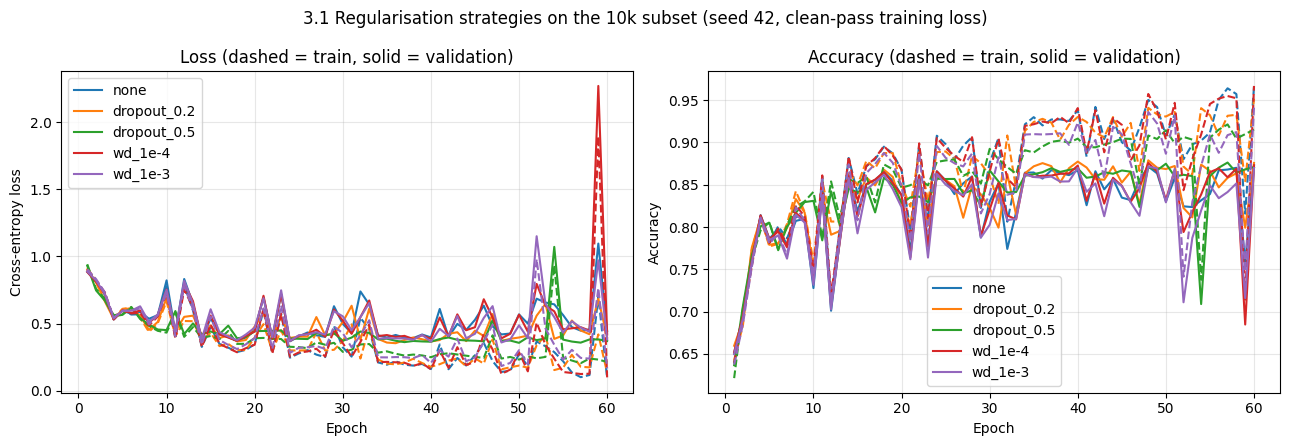

In [ ]:
print(f"{'Config':<12} {'Best val':>9} {'Ep':>3} {'Final train':>12} {'Final val':>10} {'Final gap':>10} "
      f"{'Min val loss':>13} {'Final val loss':>15}")
for name, (h, s) in explore.items():
    print(f"{name:<12} {s['best_val_acc']:>9.4f} {s['best_epoch']:>3} {s['final_train_acc']:>12.4f} "
          f"{s['final_val_acc']:>10.4f} {s['final_gap']:>10.4f} {s['min_val_loss']:>13.4f} {s['final_val_loss']:>15.4f}")

plot_curves({name: h for name, (h, s) in explore.items()},
            "3.1 Regularisation strategies on the 10k subset (seed 42, clean-pass training loss)")

Unregularised, the gap is 0.0937 and validation loss rises (0.3685 → 0.4453). Dropout 0.5 halves the gap; weight
decay 1e-4 barely helps. Accuracies differ by under 1 point. The rule selects **dropout 0.2** (87.89%).

## 3.1 / 3.2 Main comparison: no regularisation vs dropout 0.2 (seeds 42, 43, 44)

In [ ]:
SEEDS = [42, 43, 44]
main_configs = {"none": (0.0, 0.0), "dropout_0.2": (0.2, 0.0)}   # name -> (dropout, weight decay)

seed_runs = {name: {SEED: explore[name]} for name in main_configs}   # reuse the seed-42 runs

for name, (dropout, wd) in main_configs.items():
    for seed in SEEDS:
        if seed in seed_runs[name]:
            continue                                  # seed 42 already trained in the exploration
        _, hist, summ = train_reg(f"{name}_s{seed}", dropout=dropout, weight_decay=wd, seed=seed)
        seed_runs[name][seed] = (hist, summ)

none_s43 | epoch 10: train loss 0.4231 acc 0.8509 | val loss 0.4580 acc 0.8371
none_s43 | epoch 20: train loss 0.2896 acc 0.8906 | val loss 0.3944 acc 0.8571
none_s43 | epoch 30: train loss 0.1994 acc 0.9270 | val loss 0.3691 acc 0.8696
none_s43 | epoch 40: train loss 0.1623 acc 0.9398 | val loss 0.3954 acc 0.8708
none_s43 | epoch 50: train loss 0.2400 acc 0.9034 | val loss 0.5499 acc 0.8305
none_s43 | epoch 60: train loss 0.1311 acc 0.9492 | val loss 0.4638 acc 0.8655
none_s43: best val 0.8737 (epoch 39) | final train 0.9492 val 0.8655 gap 0.0837 | 51 s

none_s44 | epoch 10: train loss 0.3655 acc 0.8670 | val loss 0.4043 acc 0.8520
none_s44 | epoch 20: train loss 0.3512 acc 0.8653 | val loss 0.4400 acc 0.8361
none_s44 | epoch 30: train loss 0.4110 acc 0.8586 | val loss 0.5663 acc 0.8249
none_s44 | epoch 40: train loss 0.2874 acc 0.8956 | val loss 0.5191 acc 0.8408
none_s44 | epoch 50: train loss 0.2647 acc 0.9087 | val loss 0.5458 acc 0.8336
none_s44 | epoch 60: train loss 0.1497 acc 

In [ ]:
# First summary: best checkpoint and single final-epoch values, per seed, mean and sample std
metrics = ["best_val_acc", "final_val_acc", "final_train_acc", "final_gap", "final_val_loss"]

for name in main_configs:
    print(f"\n{name}")
    print(f"{'Seed':<6}" + "".join(f"{m:>17}" for m in metrics))
    for seed in SEEDS:
        s = seed_runs[name][seed][1]
        print(f"{seed:<6}" + "".join(f"{s[m]:>17.4f}" for m in metrics))
    values = np.array([[seed_runs[name][seed][1][m] for m in metrics] for seed in SEEDS])
    print(f"{'Mean':<6}" + "".join(f"{v:>17.4f}" for v in values.mean(axis=0)))
    print(f"{'Std':<6}" + "".join(f"{v:>17.4f}" for v in values.std(axis=0, ddof=1)))


none
Seed       best_val_acc    final_val_acc  final_train_acc        final_gap   final_val_loss
42               0.8727           0.8727           0.9664           0.0937           0.4453
43               0.8737           0.8655           0.9492           0.0837           0.4638
44               0.8754           0.8531           0.9432           0.0901           0.5230
Mean             0.8739           0.8638           0.9529           0.0892           0.4774
Std              0.0014           0.0099           0.0120           0.0051           0.0406

dropout_0.2
Seed       best_val_acc    final_val_acc  final_train_acc        final_gap   final_val_loss
42               0.8789           0.8758           0.9515           0.0757           0.3967
43               0.8785           0.8746           0.9482           0.0736           0.4000
44               0.8778           0.7973           0.8513           0.0540           0.7613
Mean             0.8784           0.8492           0.9170    

A spike at epoch 60 (seed 44, 79.73%) distorts final-epoch values, so epochs 51–60 are averaged.

#### Seed-level summary

In [ ]:
def seed_summary(name, seed):
    h, s = seed_runs[name][seed]
    train_acc_10 = np.mean(h["train_acc"][-10:])
    val_acc_10 = np.mean(h["val_acc"][-10:])
    return {
        "best_val_acc": s["best_val_acc"],                      # checkpoint rule (includes early stopping)
        "val_acc_51_60": val_acc_10,                            # mean over last 10 epochs
        "gap_51_60": train_acc_10 - val_acc_10,                 # mean train-val gap, last 10 epochs
        "min_val_loss": s["min_val_loss"],
        "val_loss_51_60": np.mean(h["val_loss"][-10:]),
        "final_val_acc": s["final_val_acc"],                    # single snapshot at epoch 60
    }

for name in main_configs:
    rows = [seed_summary(name, seed) for seed in SEEDS]
    cols = list(rows[0].keys())
    print(f"\n{name}")
    print(f"{'Seed':<6}" + "".join(f"{c:>15}" for c in cols))
    for seed, r in zip(SEEDS, rows):
        print(f"{seed:<6}" + "".join(f"{r[c]:>15.4f}" for c in cols))
    values = np.array([[r[c] for c in cols] for r in rows])
    print(f"{'Mean':<6}" + "".join(f"{v:>15.4f}" for v in values.mean(axis=0)))
    print(f"{'Std':<6}" + "".join(f"{v:>15.4f}" for v in values.std(axis=0, ddof=1)))


none
Seed     best_val_acc  val_acc_51_60      gap_51_60   min_val_loss val_loss_51_60  final_val_acc
42             0.8727         0.8413         0.0767         0.3685         0.5971         0.8727
43             0.8737         0.8424         0.0790         0.3691         0.5550         0.8655
44             0.8754         0.8571         0.0818         0.3805         0.4996         0.8531
Mean           0.8739         0.8469         0.0792         0.3727         0.5506         0.8638
Std            0.0014         0.0088         0.0026         0.0068         0.0489         0.0099

dropout_0.2
Seed     best_val_acc  val_acc_51_60      gap_51_60   min_val_loss val_loss_51_60  final_val_acc
42             0.8789         0.8490         0.0631         0.3543         0.4892         0.8758
43             0.8785         0.8509         0.0651         0.3521         0.4869         0.8746
44             0.8778         0.8596         0.0643         0.3537         0.4504         0.7973
Mean       

| Mean ± std (3 seeds) | none | dropout 0.2 |
|---|---|---|
| Gap, epochs 51–60 | 0.0792 ± 0.0026 | 0.0642 ± 0.0010 |
| Validation loss, epochs 51–60 | 0.5506 ± 0.0489 | 0.4755 ± 0.0218 |
| Best validation accuracy | 0.8739 ± 0.0014 | 0.8784 ± 0.0006 |

Dropout reduced overfitting for every seed, but the accuracy gain is small. Early stopping helped more (about
2.5–2.7 points).

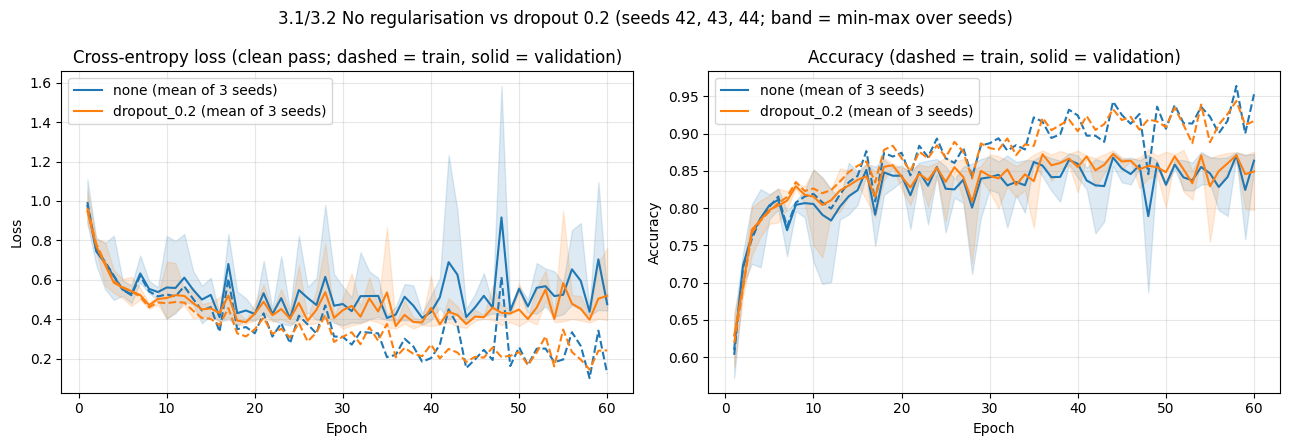

In [ ]:
# Mean of the 3 seeds at every epoch; the shaded band runs from the lowest to the highest seed
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs = np.arange(1, len(seed_runs["none"][SEEDS[0]][0]["val_acc"]) + 1)   # 1..60

for name, colour in [("none", "tab:blue"), ("dropout_0.2", "tab:orange")]:
    for ax, key in [(axes[0], "loss"), (axes[1], "acc")]:
        train = np.array([seed_runs[name][s][0][f"train_{key}"] for s in SEEDS])   # shape (3 seeds, 60 epochs)
        val = np.array([seed_runs[name][s][0][f"val_{key}"] for s in SEEDS])

        ax.plot(epochs, train.mean(axis=0), linestyle="--", color=colour)
        ax.plot(epochs, val.mean(axis=0), color=colour, label=f"{name} (mean of 3 seeds)")
        ax.fill_between(epochs, val.min(axis=0), val.max(axis=0), color=colour, alpha=0.15)

axes[0].set_title("Cross-entropy loss (clean pass; dashed = train, solid = validation)")
axes[1].set_title("Accuracy (dashed = train, solid = validation)")
for ax, ylabel in zip(axes, ["Loss", "Accuracy"]):
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("3.1/3.2 No regularisation vs dropout 0.2 (seeds 42, 43, 44; band = min-max over seeds)")
plt.tight_layout()
plt.show()

After about 15 epochs, unregularised validation loss drifts up.

## 3.2 Randomness

Controlled: split, subset, initial weights, dropout masks and batch order. Seed std is under 0.0015 for best accuracy
but up to 0.0450 for single final epochs. Three seeds give a rough estimate.

## Part 3 summary

Dropout consistently reduces overfitting; early stopping helps more.

## Part 3 summary

- On 10,000 images, the unregularised network overfits clearly (late gap **0.0792**, validation loss rising from
  **0.3727** to **0.5506**).
- **Dropout 0.2** reduces overfitting for every seed (late gap **0.0642**) and slightly raises best validation
  accuracy (**0.8739 → 0.8784**), but the accuracy gain is small compared with seed variability.
- **Early stopping** (the checkpoint rule) gives a larger benefit than dropout.
- **Single final-epoch values are unreliable** under plain SGD at lr 0.1; means over the last 10 epochs are fairer.

# Part 4: Clustering: structure without labels

**Objective:** cluster raw pixels without labels, then interpret. K-means alternates assignment and update steps to
minimise squared distance, reaching only a local minimum.

## 4.1 Choosing K and stability

In [ ]:
def pixels(dataset, indices):
    """Flatten images to rows of 784 raw pixel values in 0-1 (no other transformation)."""
    return dataset.data[indices].reshape(-1, 784).numpy().astype(np.float64) / 255.0


Xc_train = pixels(train_data, cluster_train_indices)   # 3,000 images: fit centroids
Xc_val = pixels(train_data, cluster_val_indices)       # 1,000 images: choose K

# Labels are kept separately and are NOT used until 4.2 (interpretation only)
yc_train = train_data.targets[cluster_train_indices].numpy()
yc_val = train_data.targets[cluster_val_indices].numpy()

print("Clustering train:", Xc_train.shape, " validation:", Xc_val.shape)
print("Pixel range:", Xc_train.min(), "to", Xc_train.max())

Clustering train: (3000, 784)  validation: (1000, 784)
Pixel range: 0.0 to 1.0


#### K sweep (no labels)

In [ ]:
K_values = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30]

# Every setting needed to reproduce the fits
KM_SETTINGS = dict(init="k-means++", n_init=10, max_iter=300, tol=1e-4, algorithm="lloyd")

km_results = []
for K in K_values:
    start = time.time()
    km = KMeans(n_clusters=K, random_state=SEED, **KM_SETTINGS).fit(Xc_train)   # no labels
    elapsed = time.time() - start

    # Validation: assign each validation image to its nearest TRAINING centroid
    val_assign = km.predict(Xc_val)
    val_J = np.sum((Xc_val - km.cluster_centers_[val_assign]) ** 2)

    km_results.append({
        "K": K,
        "train_J": km.inertia_ / len(Xc_train),       # J per image, so train and val are comparable
        "val_J": val_J / len(Xc_val),
        "train_sil": silhouette_score(Xc_train, km.labels_),
        "val_sil": silhouette_score(Xc_val, val_assign),
        "iters": km.n_iter_,
        "time_s": elapsed,
    })
    r = km_results[-1]
    print(f"K = {K:>2}: J/img train {r['train_J']:.2f} val {r['val_J']:.2f} | "
          f"silhouette train {r['train_sil']:.3f} val {r['val_sil']:.3f} | {r['iters']} iters, {elapsed:.1f} s")

K =  2: J/img train 53.85 val 52.99 | silhouette train 0.191 val 0.191 | 13 iters, 1.2 s
K =  3: J/img train 46.41 val 45.62 | silhouette train 0.184 val 0.185 | 10 iters, 2.8 s
K =  4: J/img train 41.88 val 41.39 | silhouette train 0.180 val 0.172 | 15 iters, 2.0 s
K =  5: J/img train 39.23 val 39.01 | silhouette train 0.155 val 0.143 | 17 iters, 1.6 s
K =  6: J/img train 36.70 val 36.39 | silhouette train 0.157 val 0.149 | 19 iters, 1.7 s
K =  8: J/img train 33.66 val 33.50 | silhouette train 0.157 val 0.151 | 35 iters, 2.1 s
K = 10: J/img train 31.63 val 31.55 | silhouette train 0.159 val 0.152 | 43 iters, 4.0 s
K = 12: J/img train 30.13 val 30.03 | silhouette train 0.137 val 0.130 | 18 iters, 2.7 s
K = 15: J/img train 28.34 val 28.29 | silhouette train 0.126 val 0.122 | 36 iters, 3.1 s
K = 20: J/img train 26.55 val 26.63 | silhouette train 0.107 val 0.103 | 54 iters, 3.5 s
K = 25: J/img train 25.35 val 25.69 | silhouette train 0.103 val 0.093 | 37 iters, 6.0 s
K = 30: J/img train 2

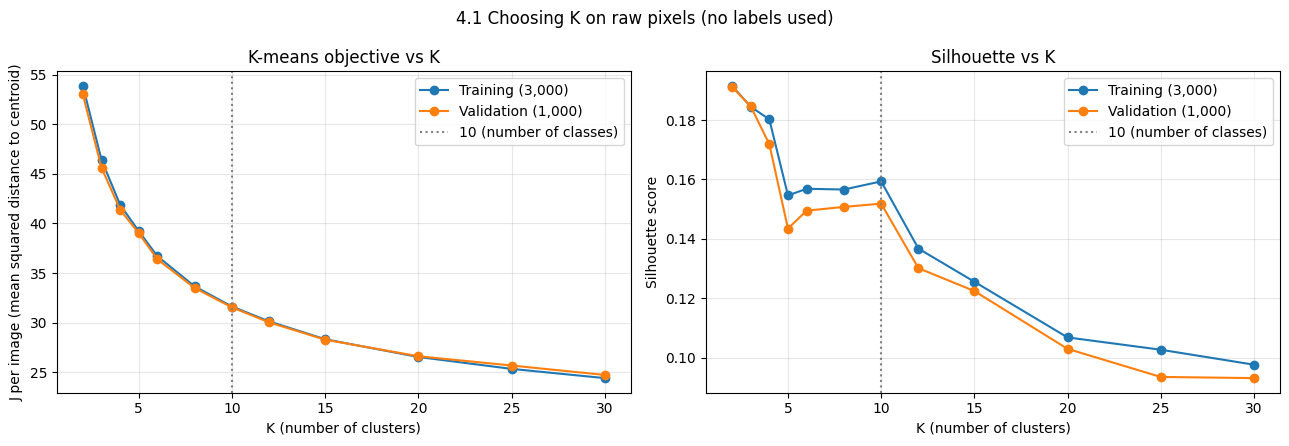

In [ ]:
Ks = [r["K"] for r in km_results]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(Ks, [r["train_J"] for r in km_results], marker="o", label="Training (3,000)")
axes[0].plot(Ks, [r["val_J"] for r in km_results], marker="o", label="Validation (1,000)")
axes[0].set_ylabel("J per image (mean squared distance to centroid)")
axes[0].set_title("K-means objective vs K")

axes[1].plot(Ks, [r["train_sil"] for r in km_results], marker="o", label="Training (3,000)")
axes[1].plot(Ks, [r["val_sil"] for r in km_results], marker="o", label="Validation (1,000)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette vs K")

for ax in axes:
    ax.axvline(10, linestyle=":", color="gray", label="10 (number of classes)")
    ax.set_xlabel("K (number of clusters)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("4.1 Choosing K on raw pixels (no labels used)")
plt.tight_layout()
plt.show()

J has no clear elbow. Silhouette peaks at K = 2 (0.191) and locally at **K = 10 (0.152)** before dropping, so K = 10
is chosen. Values below 0.2 mean overlapping groups.

#### Stability at K = 10

In [ ]:
K_CHOSEN = 10
STAB_SEEDS = list(range(10))   # 10 different random starting points

protocols = {
    "A: random init, 1 restart":     dict(init="random",    n_init=1),
    "B: k-means++, 1 restart":       dict(init="k-means++", n_init=1),
    "C: k-means++, 10 restarts":     dict(init="k-means++", n_init=10),
}

stability = {}
for pname, settings in protocols.items():
    runs = [KMeans(n_clusters=K_CHOSEN, max_iter=300, tol=1e-4, algorithm="lloyd",
                   random_state=s, **settings).fit(Xc_train) for s in STAB_SEEDS]

    Js = np.array([r.inertia_ / len(Xc_train) for r in runs])
    # Agreement between every pair of runs (45 pairs); no class labels involved
    aris = [adjusted_rand_score(runs[i].labels_, runs[j].labels_)
            for i in range(len(runs)) for j in range(i + 1, len(runs))]

    stability[pname] = {"runs": runs, "J": Js, "ari": np.array(aris)}
    print(f"{pname:<28} J/img mean {Js.mean():.3f}  std {Js.std(ddof=1):.3f}  "
          f"min {Js.min():.3f}  max {Js.max():.3f} | pairwise ARI mean {np.mean(aris):.3f}  min {np.min(aris):.3f}")

A: random init, 1 restart    J/img mean 32.182  std 0.524  min 31.633  max 33.586 | pairwise ARI mean 0.658  min 0.492
B: k-means++, 1 restart      J/img mean 32.079  std 0.366  min 31.633  max 32.923 | pairwise ARI mean 0.670  min 0.463
C: k-means++, 10 restarts    J/img mean 31.680  std 0.075  min 31.633  max 31.820 | pairwise ARI mean 0.885  min 0.704


Single starts agree moderately (ARI 0.658–0.670); ten restarts raise agreement to 0.885.

## 4.2 Interpreting clusters

In [ ]:
# Final fits with the fixed protocol (no labels)
km10 = KMeans(n_clusters=10, random_state=SEED, **KM_SETTINGS).fit(Xc_train)
km2 = KMeans(n_clusters=2, random_state=SEED, **KM_SETTINGS).fit(Xc_train)
print(f"K = 10: J/img {km10.inertia_ / len(Xc_train):.3f}   K = 2: J/img {km2.inertia_ / len(Xc_train):.3f}")

K = 10: J/img 31.633   K = 2: J/img 53.853


J per image (**31.633** and **53.853**) matches the sweep, so these are the same solutions.

In [ ]:
short_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]

def composition(cluster_labels, true_labels):
    """Count how many images of each class fall in each cluster."""
    table = pd.crosstab(cluster_labels, true_labels)
    table.columns = [short_names[c] for c in table.columns]
    table.index.name = "Cluster"
    table["Size"] = table.sum(axis=1)
    table["Majority"] = table[short_names].idxmax(axis=1)
    table["Purity"] = (table[short_names].max(axis=1) / table["Size"]).round(2)
    return table.sort_values("Majority")

comp10 = composition(km10.labels_, yc_train)
print(comp10.to_string())

purity10 = comp10[short_names].max(axis=1).sum() / len(yc_train)
print(f"\nOverall purity (K = 10): {purity10:.3f}")
print(f"ARI between clusters and classes (K = 10): {adjusted_rand_score(yc_train, km10.labels_):.3f}")

print("\nK = 2 composition:")
print(composition(km2.labels_, yc_train).to_string())

         T-shirt  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Boot  Size Majority  Purity
Cluster                                                                                                   
0              4        0         2      2     0       1      0        0  119     0   128      Bag    0.93
7              0        0         2      0     0       2      1        1  116     0   122      Bag    0.95
4              0        0         0      0     0       6      0        1    0    86    93     Boot    0.92
8              0        0         0      0     0      18      0       15    0   190   223     Boot    0.85
6              8        7       169      7   170       0    113        0   10     0   484     Coat    0.35
1             32       11        29     25    11     192     40       28   25     5   398   Sandal    0.48
9             68       10        93     23    65       4     98        0   14     3   378    Shirt    0.26
5              0        0         0  

Purity 0.557, ARI 0.353. Bag and Boot split into two clusters each; tops merge, and Trouser joins Dress.

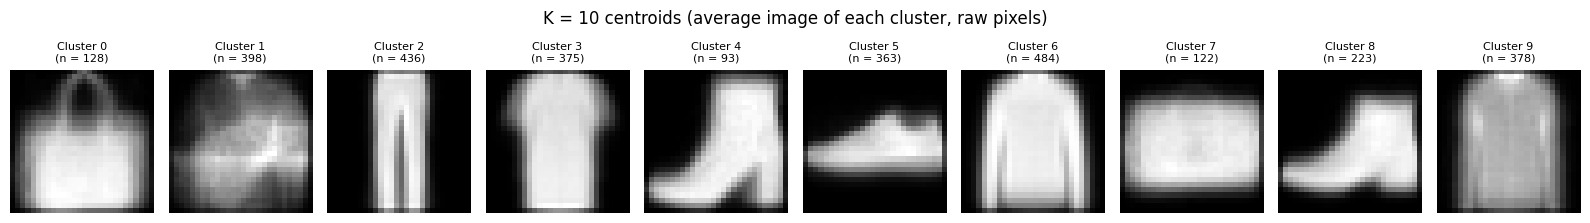

In [ ]:
# Each centroid is the average image of its cluster
fig, axes = plt.subplots(1, 10, figsize=(16, 2.4))
for c, ax in enumerate(axes):
    ax.imshow(km10.cluster_centers_[c].reshape(28, 28), cmap="gray", interpolation="nearest")
    ax.set_title(f"Cluster {c}\n(n = {np.sum(km10.labels_ == c)})", fontsize=8)
    ax.axis("off")
plt.suptitle("K = 10 centroids (average image of each cluster, raw pixels)")
plt.tight_layout()
plt.show()

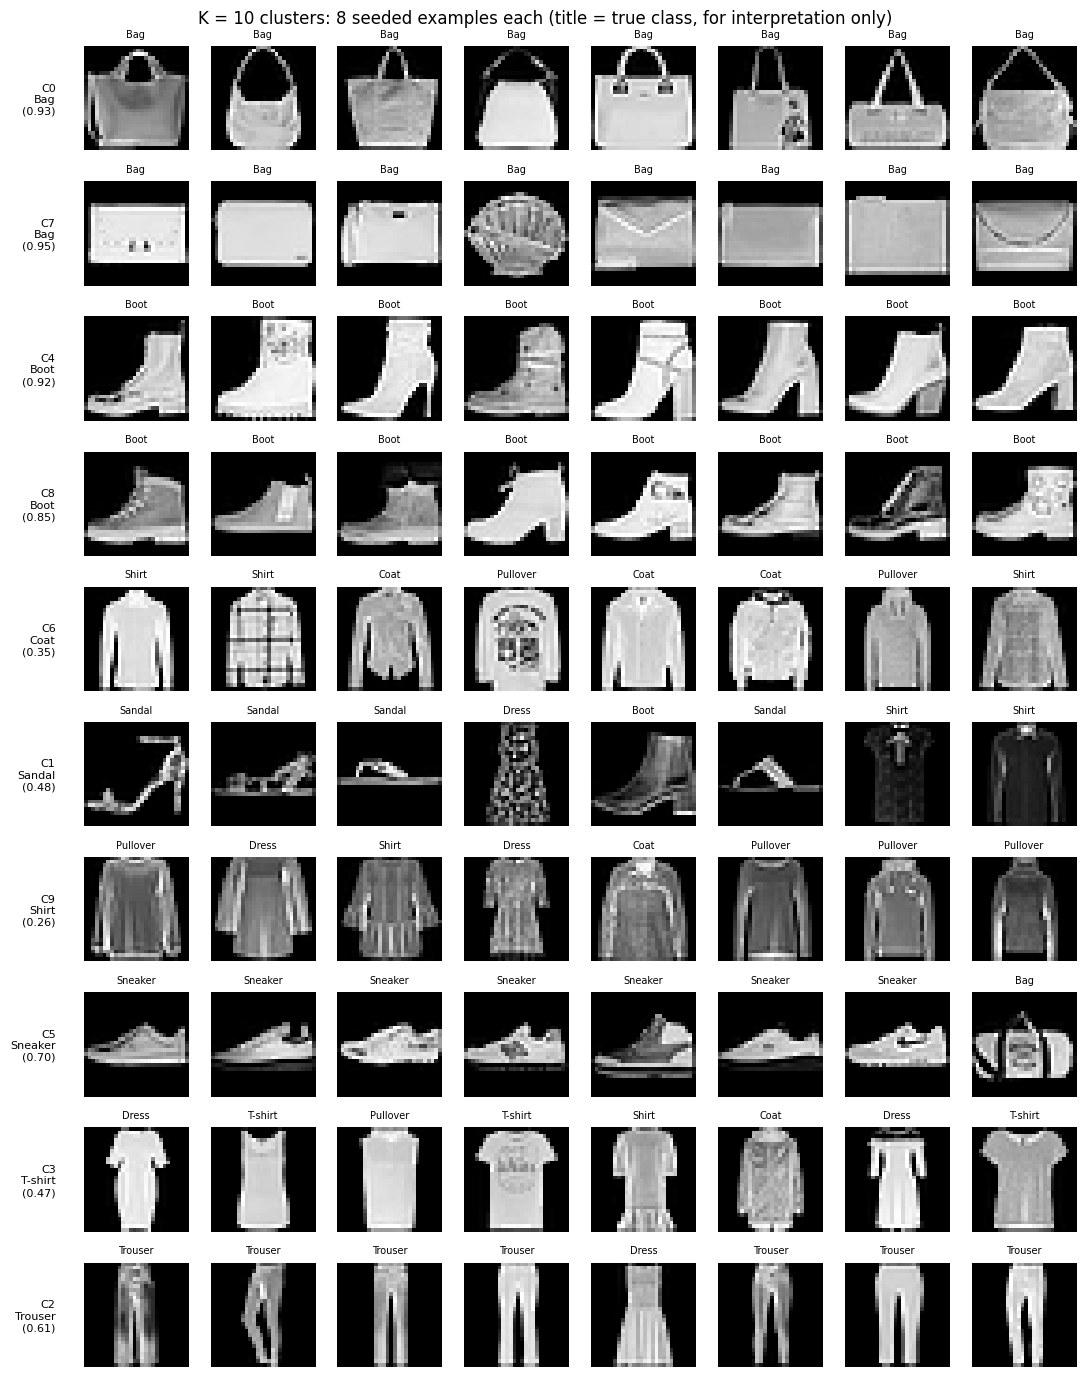

In [ ]:
rng_clusters = np.random.default_rng(SEED)
cluster_order = comp10.index.tolist()     # same order as the composition table
n_examples = 8

fig, axes = plt.subplots(len(cluster_order), n_examples, figsize=(11, 14))
for row, c in enumerate(cluster_order):
    members = np.where(km10.labels_ == c)[0]
    chosen = rng_clusters.choice(members, size=n_examples, replace=False)
    for col, i in enumerate(chosen):
        ax = axes[row, col]
        ax.imshow(Xc_train[i].reshape(28, 28), cmap="gray", interpolation="nearest")
        ax.set_title(short_names[yc_train[i]], fontsize=7)
        ax.axis("off")
    axes[row, 0].text(-8, 14, f"C{c}\n{comp10.loc[c, 'Majority']}\n({comp10.loc[c, 'Purity']:.2f})",
                      ha="right", va="center", fontsize=8)
plt.suptitle("K = 10 clusters: 8 seeded examples each (title = true class, for interpretation only)")
plt.tight_layout()
plt.show()

Bags split by handles, boots by height. One cluster mixes thin sandals with dark items.

In [ ]:
ink = Xc_train.mean(axis=1)    # average pixel brightness of each image (no labels)

print("Mean brightness per K = 10 cluster:")
for c in cluster_order:
    print(f"  C{c} ({comp10.loc[c, 'Majority']:<7}) {ink[km10.labels_ == c].mean():.3f}")

clothing = np.isin(yc_train, [0, 1, 2, 3, 4, 6])   # T-shirt, Trouser, Pullover, Dress, Coat, Shirt
fw_side = np.argmax([np.isin(yc_train[km2.labels_ == k], [5, 7, 9]).mean() for k in [0, 1]])   # K=2 cluster holding most footwear
print(f"\nClothing images on the clothing side (K = 2): mean brightness {ink[clothing & (km2.labels_ != fw_side)].mean():.3f}")
print(f"Clothing images on the footwear side (K = 2): mean brightness {ink[clothing & (km2.labels_ == fw_side)].mean():.3f}")

Mean brightness per K = 10 cluster:
  C0 (Bag    ) 0.366
  C7 (Bag    ) 0.391
  C4 (Boot   ) 0.380
  C8 (Boot   ) 0.273
  C6 (Coat   ) 0.456
  C1 (Sandal ) 0.121
  C9 (Shirt  ) 0.252
  C5 (Sneaker) 0.170
  C3 (T-shirt) 0.377
  C2 (Trouser) 0.225

Clothing images on the clothing side (K = 2): mean brightness 0.361
Clothing images on the footwear side (K = 2): mean brightness 0.177


That cluster is darkest (0.121): raw-pixel distance follows outline and brightness, so clusters need not match classes.

## 4.3 Connection to classification

K-means mixes the tops the classifiers confused. kNN shares its pixel distance and sandal errors. Labels let
classifiers separate Trouser and Dress.

## 4.4 Hierarchical clustering

Ward linkage (same objective as K-means) on 300 images.

In [ ]:
hier_rows, _ = train_test_split(
    np.arange(len(Xc_train)),        # rows of Xc_train
    train_size=300,
    stratify=yc_train,               # 30 per class (labels used only to build the subset)
    random_state=SEED,
)
np.save("splits/hier_indices.npy", np.array(cluster_train_indices)[hier_rows])   # original positions

Xh = Xc_train[hier_rows]
yh = yc_train[hier_rows]

start = time.time()
Z = linkage(Xh, method="ward")       # Euclidean distance, Ward linkage; no labels
print(f"Ward linkage on {len(Xh)} images: {time.time() - start:.2f} s")

Ward linkage on 300 images: 0.03 s


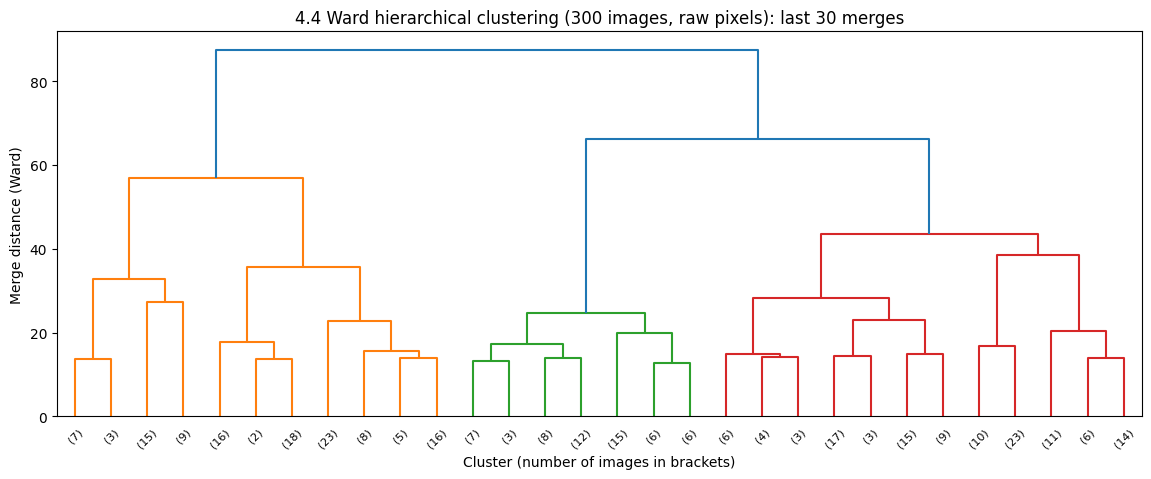

In [ ]:
# Show only the last 30 merges; the height of each join shows how different the two groups are
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_font_size=8)
plt.title("4.4 Ward hierarchical clustering (300 images, raw pixels): last 30 merges")
plt.xlabel("Cluster (number of images in brackets)")
plt.ylabel("Merge distance (Ward)")
plt.show()

In [ ]:
for k in [2, 3, 4, 6, 10]:
    h_labels = fcluster(Z, t=k, criterion="maxclust")
    comp = composition(h_labels, yh)
    print(f"\nCut into {k} clusters:")
    print(comp[["Size", "Majority", "Purity"] + short_names].to_string())

h10 = fcluster(Z, t=10, criterion="maxclust")
print(f"\nAgreement with K-means (K = 10) on the same 300 images, ARI: "
      f"{adjusted_rand_score(km10.labels_[hier_rows], h10):.3f}")
print(f"Ward K = 10 vs classes, ARI: {adjusted_rand_score(yh, h10):.3f}   "
      f"K-means K = 10 vs classes (same 300), ARI: {adjusted_rand_score(yh, km10.labels_[hier_rows]):.3f}")


Cut into 2 clusters:
         Size Majority  Purity  T-shirt  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Boot
Cluster                                                                                                   
2         178     Coat    0.16       26       27        27     27    29       0     27        0   15     0
1         122   Sandal    0.25        4        3         3      3     1      30      3       30   15    30

Cut into 3 clusters:
         Size  Majority  Purity  T-shirt  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Boot
Cluster                                                                                                    
2          57  Pullover    0.35        2        2        20      2    19       0     12        0    0     0
1         122    Sandal    0.25        4        3         3      3     1      30      3       30   15    30
3         121   Trouser    0.21       24       25         7     25    10       0     15        0

It splits footwear from clothing, then long-sleeved tops, showing nesting K-means cannot. ARI with K-means 0.746.

## Part 4 summary

Raw-pixel clusters overlap and mirror the classifiers' confusions.

# Part 5: Representations and one extension

**Objective:** repeat the clustering protocol on MLP features (5.1) and test an ensemble (5.2).

## 5.1 Raw pixels vs MLP features

128-value features from the frozen baseline MLP's last hidden layer.

In [ ]:
# The validation-selected MLP from Part 2, loaded from its saved checkpoint
feat_model = MLP(BASELINE_HIDDEN).to(device)
feat_model.load_state_dict(torch.load("checkpoints/baseline.pt", map_location=device))
feat_model.eval()
for p in feat_model.parameters():
    p.requires_grad_(False)                          # frozen: no gradients, no updates

_, check_acc = evaluate(feat_model, val_loader)
print(f"Loaded model validation accuracy: {check_acc:.4f}")   # should be 0.8960

# Encoder: Linear(784 -> 256) -> ReLU -> Linear(256 -> 128) -> ReLU  (last hidden layer)
encoder = feat_model.net[:4]
print(encoder)


def weights_checksum(model):
    """Sum of all weights, used to confirm nothing changes during extraction."""
    return sum(p.detach().double().sum().item() for p in model.parameters())


def extract(indices):
    """128-d features after the last hidden ReLU, for images in train_data."""
    x = train_data.data[indices].float().div(255.0).view(-1, 784).to(device)
    with torch.no_grad():
        return encoder(x).cpu().numpy().astype(np.float64)


before = weights_checksum(feat_model)
start = time.time()
F_train = extract(cluster_train_indices)              # same 3,000 images as Part 4
F_val = extract(cluster_val_indices)                  # same 1,000 images as Part 4
extract_time = time.time() - start
after = weights_checksum(feat_model)

print(f"\nFeatures: train {F_train.shape}, validation {F_val.shape}, extracted in {extract_time:.2f} s")
print("Weights unchanged during extraction:", before == after)
print(f"Value range: {F_train.min():.2f} to {F_train.max():.2f}")
print("Dead units (always 0 on training subset):", int((F_train.max(axis=0) == 0).sum()), "of 128")

os.makedirs("features", exist_ok=True)
np.save("features/mlp_hidden2_train.npy", F_train)
np.save("features/mlp_hidden2_val.npy", F_val)

Loaded model validation accuracy: 0.8960
Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=128, bias=True)
  (3): ReLU()
)

Features: train (3000, 128), validation (1000, 128), extracted in 0.06 s
Weights unchanged during extraction: True
Value range: 0.00 to 9.46
Dead units (always 0 on training subset): 0 of 128


In [ ]:
# Same K values and settings as Part 4, now on the 128-dimensional features
def kmeans_sweep(X_tr, X_va, label):
    """Part 4 K sweep (same K values and settings) for any representation."""
    results = []
    for K in K_values:
        km = KMeans(n_clusters=K, random_state=SEED, **KM_SETTINGS).fit(X_tr)
        va = km.predict(X_va)
        results.append({
            "K": K,
            "train_J": km.inertia_ / len(X_tr),
            "val_J": np.sum((X_va - km.cluster_centers_[va]) ** 2) / len(X_va),
            "train_sil": silhouette_score(X_tr, km.labels_),
            "val_sil": silhouette_score(X_va, va),
        })
        r = results[-1]
        print(f"{label} K = {K:>2}: J/img train {r['train_J']:.2f} val {r['val_J']:.2f} | "
              f"silhouette train {r['train_sil']:.3f} val {r['val_sil']:.3f}")
    return results


start = time.time()
feat_results = kmeans_sweep(F_train, F_val, "MLP")
print(f"\nSweep time: {time.time() - start:.0f} s")

MLP K =  2: J/img train 35.42 val 34.69 | silhouette train 0.270 val 0.266
MLP K =  3: J/img train 27.75 val 27.29 | silhouette train 0.311 val 0.307
MLP K =  4: J/img train 23.54 val 23.55 | silhouette train 0.342 val 0.333
MLP K =  5: J/img train 20.17 val 20.25 | silhouette train 0.302 val 0.293
MLP K =  6: J/img train 16.95 val 17.35 | silhouette train 0.320 val 0.305
MLP K =  8: J/img train 13.85 val 14.08 | silhouette train 0.324 val 0.319
MLP K = 10: J/img train 12.30 val 12.50 | silhouette train 0.299 val 0.292
MLP K = 12: J/img train 11.16 val 11.25 | silhouette train 0.307 val 0.304
MLP K = 15: J/img train 9.79 val 9.81 | silhouette train 0.288 val 0.283
MLP K = 20: J/img train 8.61 val 8.78 | silhouette train 0.238 val 0.226
MLP K = 25: J/img train 7.88 val 8.16 | silhouette train 0.218 val 0.201
MLP K = 30: J/img train 7.37 val 7.65 | silhouette train 0.209 val 0.189

Sweep time: 8 s


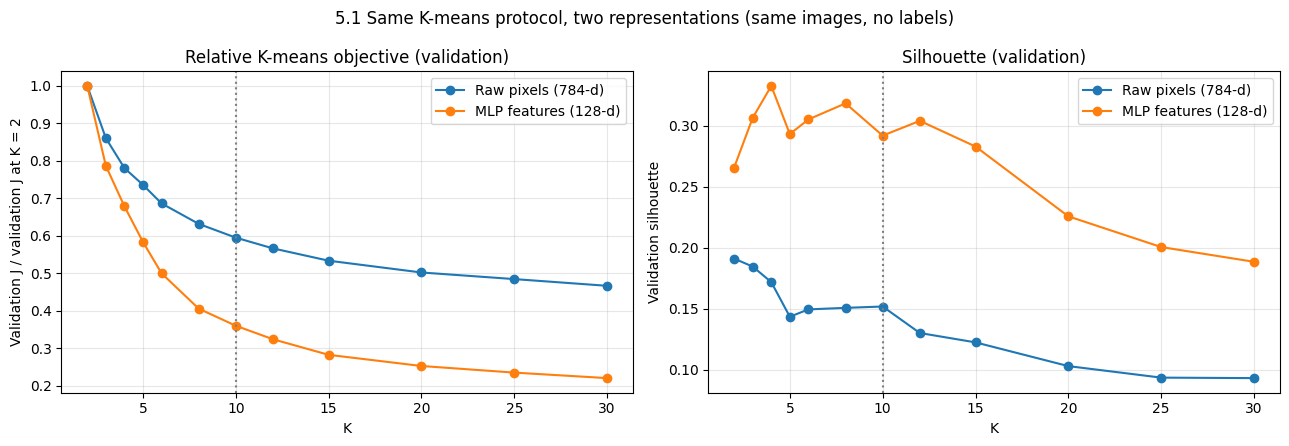

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for res, label in [(km_results, "Raw pixels (784-d)"), (feat_results, "MLP features (128-d)")]:
    Ks = [r["K"] for r in res]
    # J is in different units for each representation, so show it relative to K = 2
    axes[0].plot(Ks, [r["val_J"] / res[0]["val_J"] for r in res], marker="o", label=label)
    axes[1].plot(Ks, [r["val_sil"] for r in res], marker="o", label=label)

axes[0].set_ylabel("Validation J / validation J at K = 2")
axes[0].set_title("Relative K-means objective (validation)")
axes[1].set_ylabel("Validation silhouette")
axes[1].set_title("Silhouette (validation)")
for ax in axes:
    ax.axvline(10, linestyle=":", color="gray")
    ax.set_xlabel("K")
    ax.grid(alpha=0.3)
    ax.legend()
plt.suptitle("5.1 Same K-means protocol, two representations (same images, no labels)")
plt.tight_layout()
plt.show()

In [ ]:
# Same three stability protocols as Part 4 (3 protocols x 10 seeds) at K = 10
def stability_check(X, label):
    """Part 4 stability protocols (3 protocols x 10 seeds) at K = K_CHOSEN."""
    out = {}
    for pname, settings in protocols.items():
        runs = [KMeans(n_clusters=K_CHOSEN, max_iter=300, tol=1e-4, algorithm="lloyd",
                       random_state=s, **settings).fit(X) for s in STAB_SEEDS]
        Js = np.array([r.inertia_ / len(X) for r in runs])
        aris = [adjusted_rand_score(runs[i].labels_, runs[j].labels_)
                for i in range(len(runs)) for j in range(i + 1, len(runs))]
        out[pname] = {"J": Js, "ari": np.array(aris)}
        print(f"{label} | {pname:<28} J/img mean {Js.mean():.3f} std {Js.std(ddof=1):.3f} | "
              f"pairwise ARI mean {np.mean(aris):.3f} min {np.min(aris):.3f}")
    return out


feat_stability = stability_check(F_train, "MLP")

MLP | A: random init, 1 restart    J/img mean 13.803 std 1.565 | pairwise ARI mean 0.601 min 0.258
MLP | B: k-means++, 1 restart      J/img mean 12.721 std 0.421 | pairwise ARI mean 0.687 min 0.544
MLP | C: k-means++, 10 restarts    J/img mean 12.304 std 0.025 | pairwise ARI mean 0.934 min 0.793


In [ ]:
kmF10 = KMeans(n_clusters=10, random_state=SEED, **KM_SETTINGS).fit(F_train)   # no labels

# Labels used below for interpretation only (protocol already fixed)
compF10 = composition(kmF10.labels_, yc_train)
print("MLP features, K = 10:")
print(compF10.to_string())

def k10(results):
    return next(r for r in results if r["K"] == 10)

rows = [
    ("Validation silhouette (K = 10)", k10(km_results)["val_sil"], k10(feat_results)["val_sil"]),
    ("Stability: mean pairwise ARI (10 restarts)",
     stability["C: k-means++, 10 restarts"]["ari"].mean(), feat_stability["C: k-means++, 10 restarts"]["ari"].mean()),
    ("Purity vs classes", comp10[short_names].max(axis=1).sum() / len(yc_train),
     compF10[short_names].max(axis=1).sum() / len(yc_train)),
    ("ARI vs classes", adjusted_rand_score(yc_train, km10.labels_), adjusted_rand_score(yc_train, kmF10.labels_)),
]
print(f"\n{'Measure (same 3,000 images, K = 10)':<44} {'Raw pixels':>11} {'MLP features':>13}")
for name, raw, feat in rows:
    print(f"{name:<44} {raw:>11.3f} {feat:>13.3f}")

print(f"\nAgreement between raw-pixel and feature clusterings (ARI): "
      f"{adjusted_rand_score(km10.labels_, kmF10.labels_):.3f}")

MLP features, K = 10:
         T-shirt  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Boot  Size Majority  Purity
Cluster                                                                                                   
5              1        0         0      0     0       0      0        0  106     0   107      Bag    0.99
8              3        0         0      0     0       0      0        0  167     0   170      Bag    0.98
2              0        0         0      0     0       5      0        2    0   277   284     Boot    0.98
3              0        4       130      0   207       0     30        0    0     0   371     Coat    0.56
6             20       20         1    253     2       0     11        0    0     0   307    Dress    0.82
7              0        0         0      0     0     277      0        0    0     0   277   Sandal    1.00
9             33        6       165     44    91       1    218        0   26     0   584    Shirt    0.37
4              

| K = 10, same images | Raw pixels | MLP features |
|---|---|---|
| Silhouette | 0.152 | 0.292 |
| Purity | 0.557 | 0.772 |
| ARI vs classes | 0.353 | 0.603 |

Sandal and Trouser become pure; tops still mix.

In [ ]:
# The network trained on the clustering-train images, but not on the clustering-validation images
def purity(clusters, labels):
    """Fraction of images that are in their cluster's majority class."""
    return pd.crosstab(clusters, labels).max(axis=1).sum() / len(labels)

raw_val_clusters = km10.predict(Xc_val)       # nearest raw-pixel centroid
feat_val_clusters = kmF10.predict(F_val)      # nearest feature centroid

print(f"{'Clustering-validation images (1,000)':<38} {'Raw pixels':>11} {'MLP features':>13}")
print(f"{'Purity vs classes':<38} {purity(raw_val_clusters, yc_val):>11.3f} {purity(feat_val_clusters, yc_val):>13.3f}")
print(f"{'ARI vs classes':<38} {adjusted_rand_score(yc_val, raw_val_clusters):>11.3f} "
      f"{adjusted_rand_score(yc_val, feat_val_clusters):>13.3f}")

Clustering-validation images (1,000)    Raw pixels  MLP features
Purity vs classes                            0.566         0.763
ARI vs classes                               0.354         0.579


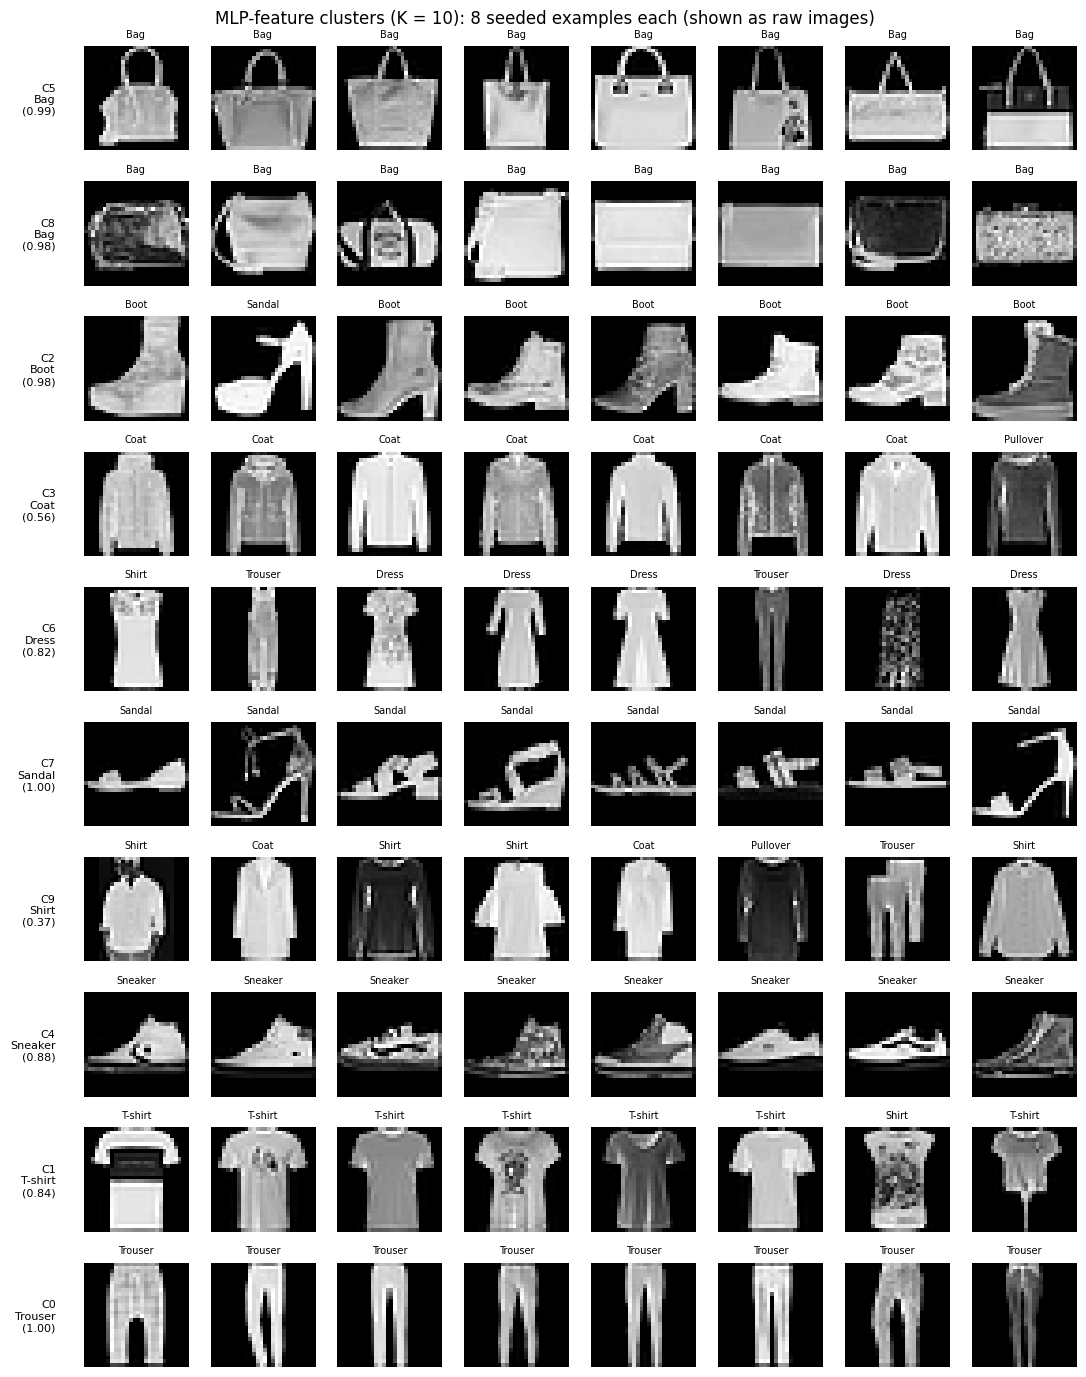

In [ ]:
rng_feat = np.random.default_rng(SEED)
order_F = compF10.index.tolist()

fig, axes = plt.subplots(len(order_F), 8, figsize=(11, 14))
for row, c in enumerate(order_F):
    members = np.where(kmF10.labels_ == c)[0]
    chosen = rng_feat.choice(members, size=8, replace=False)
    for col, i in enumerate(chosen):
        ax = axes[row, col]
        ax.imshow(Xc_train[i].reshape(28, 28), cmap="gray", interpolation="nearest")
        ax.set_title(short_names[yc_train[i]], fontsize=7)
        ax.axis("off")
    axes[row, 0].text(-8, 14, f"C{c}\n{compF10.loc[c, 'Majority']}\n({compF10.loc[c, 'Purity']:.2f})",
                      ha="right", va="center", fontsize=8)
plt.suptitle("MLP-feature clusters (K = 10): 8 seeded examples each (shown as raw images)")
plt.tight_layout()
plt.show()

In [ ]:
# Additional check: standardise features (fitted on training features only), so every unit counts equally
feat_scaler = StandardScaler().fit(F_train)          # fitted on TRAINING features only (R2)
Fs_train = feat_scaler.transform(F_train)
Fs_val = feat_scaler.transform(F_val)

kmFs10 = KMeans(n_clusters=10, random_state=SEED, **KM_SETTINGS).fit(Fs_train)
print(f"Standardised features, K = 10: validation silhouette "
      f"{silhouette_score(Fs_val, kmFs10.predict(Fs_val)):.3f} | "
      f"ARI vs classes {adjusted_rand_score(yc_train, kmFs10.labels_):.3f}")

Standardised features, K = 10: validation silhouette 0.247 | ARI vs classes 0.658


Standardising raised ARI but lowered silhouette; labels did not change the protocol. The representation drives the
gain, but labels shaped it.

## 5.2 Route B: ensembling

Members: logistic regression, kNN, MLP. Higher validation accuracy selects the rule.

In [ ]:
member_time = {}

start = time.time()
P_lr = final_log_reg.predict_proba(X_val_scaled)          # logistic regression probabilities
member_time["LogReg"] = time.time() - start
pred_lr = P_lr.argmax(axis=1)

start = time.time()
pred_knn = final_knn.predict(X_val)                       # kNN: predictions only
member_time["kNN"] = time.time() - start

start = time.time()
x_val_mlp = train_data.data[val_indices].float().div(255.0).view(-1, 784).to(device)
with torch.no_grad():
    P_mlp = torch.softmax(feat_model(x_val_mlp), dim=1).cpu().numpy()   # MLP probabilities
member_time["MLP"] = time.time() - start
pred_mlp = P_mlp.argmax(axis=1)

for name, pred in [("LogReg", pred_lr), ("kNN", pred_knn), ("MLP", pred_mlp)]:
    print(f"{name:<7} validation accuracy {accuracy_score(y_val, pred):.4f}   "
          f"prediction time {member_time[name]:.2f} s")

LogReg  validation accuracy 0.8640   prediction time 0.03 s
kNN     validation accuracy 0.8617   prediction time 28.74 s
MLP     validation accuracy 0.8960   prediction time 0.11 s


In [ ]:
# Rule (a): average the probabilities of the two probabilistic members
pred_avg = ((P_lr + P_mlp) / 2).argmax(axis=1)

# Rule (b): majority vote of all three; if all three disagree, the MLP decides
pred_vote = np.where(pred_lr == pred_knn, pred_lr, pred_mlp)

acc_avg = accuracy_score(y_val, pred_avg)
acc_vote = accuracy_score(y_val, pred_vote)
print(f"(a) Average probabilities (LogReg + MLP): validation accuracy {acc_avg:.4f}")
print(f"(b) Majority vote (LogReg + kNN + MLP):   validation accuracy {acc_vote:.4f}")

selected_rule = "average" if acc_avg >= acc_vote else "vote"
pred_ens = pred_avg if selected_rule == "average" else pred_vote
print(f"\nSelected rule: {selected_rule}")

(a) Average probabilities (LogReg + MLP): validation accuracy 0.8931
(b) Majority vote (LogReg + kNN + MLP):   validation accuracy 0.8925

Selected rule: average


In [ ]:
all_preds = {"LogReg": pred_lr, "kNN": pred_knn, "MLP": pred_mlp, "Ensemble": pred_ens}

print(f"{'Class':<12} {'Support':>7}" + "".join(f"{n:>10}" for n in all_preds) + f"{'Ens - MLP':>11}")
for c, cname in enumerate(class_names):
    mask = (y_val == c)
    recalls = [np.mean(p[mask] == c) for p in all_preds.values()]
    print(f"{cname:<12} {mask.sum():>7}" + "".join(f"{r:>10.3f}" for r in recalls)
          + f"{recalls[3] - recalls[2]:>+11.3f}")
print(f"{'Overall':<12} {len(y_val):>7}" + "".join(f"{accuracy_score(y_val, p):>10.4f}" for p in all_preds.values()))

Class        Support    LogReg       kNN       MLP  Ensemble  Ens - MLP
T-shirt/top     1000     0.851     0.900     0.929     0.906     -0.023
Trouser         1000     0.969     0.964     0.979     0.975     -0.004
Pullover        1000     0.768     0.808     0.747     0.776     +0.029
Dress           1000     0.872     0.857     0.907     0.895     -0.012
Coat            1000     0.785     0.755     0.899     0.873     -0.026
Sandal          1000     0.943     0.828     0.967     0.966     -0.001
Shirt           1000     0.622     0.622     0.640     0.650     +0.010
Sneaker         1000     0.928     0.957     0.955     0.950     -0.005
Bag             1000     0.952     0.954     0.961     0.965     +0.004
Ankle boot      1000     0.950     0.972     0.976     0.975     -0.001
Overall        10000    0.8640    0.8617    0.8960    0.8931


vs LogReg  fixed  406   broken  115   net  +291
vs kNN     fixed  668   broken  354   net  +314
vs MLP     fixed  134   broken  163   net   -29


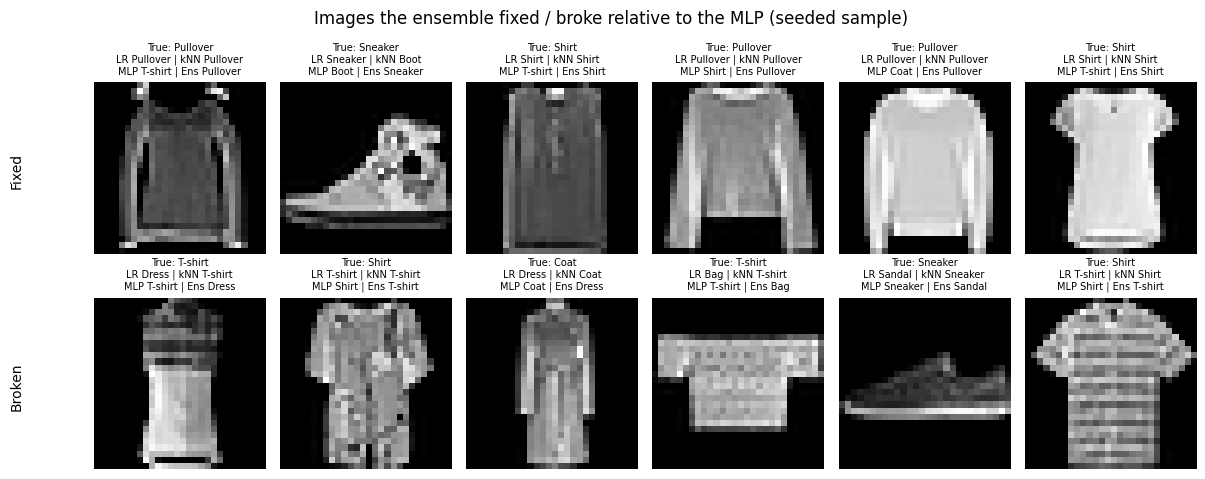

In [ ]:
ens_correct = (pred_ens == y_val)
for name in ["LogReg", "kNN", "MLP"]:
    member_correct = (all_preds[name] == y_val)
    fixed = np.sum(ens_correct & ~member_correct)      # member wrong, ensemble right
    broken = np.sum(~ens_correct & member_correct)     # member right, ensemble wrong
    print(f"vs {name:<7} fixed {fixed:>4}   broken {broken:>4}   net {fixed - broken:>+5}")

# Seeded examples of images fixed and broken relative to the MLP
mlp_correct = (pred_mlp == y_val)
fixed_rows = np.where(ens_correct & ~mlp_correct)[0]
broken_rows = np.where(~ens_correct & mlp_correct)[0]

rng_ens = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 6, figsize=(12, 5))
for row, (rows_, title) in enumerate([(fixed_rows, "Fixed"), (broken_rows, "Broken")]):
    chosen = rng_ens.choice(rows_, size=min(6, len(rows_)), replace=False)
    for col, i in enumerate(chosen):
        ax = axes[row, col]
        ax.imshow(X_val[i].reshape(28, 28), cmap="gray", interpolation="nearest")
        ax.set_title(f"True: {short_names[y_val[i]]}\nLR {short_names[pred_lr[i]]} | "
                     f"kNN {short_names[pred_knn[i]]}\nMLP {short_names[pred_mlp[i]]} | "
                     f"Ens {short_names[pred_ens[i]]}", fontsize=7)
        ax.axis("off")
    axes[row, 0].text(-12, 14, title, rotation=90, va="center", ha="right", fontsize=10)
plt.suptitle("Images the ensemble fixed / broke relative to the MLP (seeded sample)")
plt.tight_layout()
plt.show()

In [ ]:
# Members used by the selected rule
ens_members = ["LogReg", "MLP"] if selected_rule == "average" else ["LogReg", "kNN", "MLP"]

# An ensemble must run every member, so its prediction time is the sum of theirs
ens_time = sum(member_time[m] for m in ens_members)

# How many numbers each model has to store to make predictions
stored = {
    "LogReg": final_log_reg.coef_.size + final_log_reg.intercept_.size + 2 * 784,  # weights + biases + scaler mean/std
    "kNN": X_train.size + y_train.size,                                            # all 50,000 training images and labels
    "MLP": sum(p.numel() for p in feat_model.parameters()),                        # all weights, including frozen ones
}

print(f"{'Model':<10} {'Prediction time (10k)':>22} {'Numbers stored':>15}")
for m in ["LogReg", "kNN", "MLP"]:
    print(f"{m:<10} {member_time[m]:>20.2f} s {stored[m]:>15,}")
print(f"{'Ensemble':<10} {ens_time:>20.2f} s {sum(stored[m] for m in ens_members):>15,}"
      f"   ({ens_time / member_time['MLP']:.1f}x the MLP's prediction time)")

Model       Prediction time (10k)  Numbers stored
LogReg                     0.03 s           9,418
kNN                       28.74 s      39,250,000
MLP                        0.11 s         235,146
Ensemble                   0.14 s         244,564   (1.3x the MLP's prediction time)


Cost 1.3× the MLP for no gain: not justified.

**Other routes.** Route A reuses a frozen pre-trained encoder (resource: checkpoint download; risk: domain shift). Route C averages
over shifted views (resource: extra passes). C is next: cheap and tests shift sensitivity. Untested routes are not
ranked.

## Part 5 summary

Learned features cluster better; the ensemble did not help.

# Experiment register (R3)

All experiments use the 50,000 / 10,000 stratified split (seed 42) and are evaluated on validation unless stated.

| ID | Question | Changed variable | Fixed conditions | Seed | Result | Output |
|---|---|---|---|---|---|---|
| EXP-01 | Baseline logistic regression | none | C = 1, max_iter 1000, standardised (scaler fitted on train) | 42 | train 0.8879, val 0.8548; 883 iterations; 312.4 s | Part 1.1 |
| EXP-02 | Baseline kNN | none | k = 5, 0–1 pixels; train acc on 5k sample | 42 | train 0.8978, val 0.8595; predict 34.7 s | Part 1.1 |
| EXP-03 | Effect of k | k ∈ {1, 3, 5, 7, 11, 15, 25, 51} | as EXP-02 | 42 | best val 0.8617 at k = 7; k = 1 gap 0.1498 | Part 1.4 |
| EXP-04 | Effect of C | C from 0.0001 to 100 | 10k training subset, max_iter 1000 | 42 | best val 0.8518 at C = 0.01; C = 100 not converged (kept as an informative failure) | Part 1.4 |
| EXP-05 | Does C = 100 converge with more iterations? | max_iter 1000 → 3000 | as EXP-04 | 42 | 1,510 iterations; val 0.7704; conclusion unchanged | Part 1.4 |
| EXP-06 | Best C on all 50k | C ∈ {0.01, 0.1, 1} | full training set | 42 | val 0.8640 / 0.8613 / 0.8548; C = 0.01 selected | Part 1.4 |
| EXP-07 | Per-class metrics and errors | none | LR C = 0.01, kNN k = 7 | 42 | val 0.8640 vs 0.8617; Shirt hardest (recall 0.622) | Parts 1.2, 1.3 |
| EXP-08 | Shirt threshold at 5:1 cost | threshold 0.05–0.95 | final LR | 42 | t = 0.20, cost 1,707 vs 2,444 at 0.5 | Part 1.5 |
| EXP-09 | Baseline MLP | none | [256, 128], SGD lr 0.1, batch 64, 20 epochs | 42 | best val 0.8960 (epoch 16); `checkpoints/baseline.pt` | Part 2.1 |
| EXP-10 | Capacity | hidden layers [32] / [256, 128] / [1024, 512] | baseline recipe | 42 | best val 0.8746 / 0.8960 / 0.8928 | Part 2.2 |
| EXP-11 | Learning rate | lr 0.01 / 0.1 / 0.5 | baseline architecture | 42 | best val 0.8610 / 0.8960 / 0.8915; mean ep 11–20: 0.8558 / 0.8679 / 0.8668 | Part 2.3 |
| EXP-12 | Regularisation strategies | none, dropout 0.2/0.5, weight decay 1e-4/1e-3 | 10k subset, 60 epochs | 42 | dropout 0.2 selected (0.8789); dropout 0.5 smallest gap (0.0444) | Part 3.1 |
| EXP-13 | None vs dropout 0.2 over seeds | seed 42 / 43 / 44 | as EXP-12 | 42–44 | late gap 0.0792 vs 0.0642; best val 0.8739 vs 0.8784 | Parts 3.1, 3.2 |
| EXP-14 | Choosing K (raw pixels) | K from 2 to 30 | 3k clustering subset, k-means++, n_init 10 | 42 | K = 10 (val silhouette 0.152) | Part 4.1 |
| EXP-15 | Stability at K = 10 | 3 protocols × 10 seeds | raw pixels | 0–9 | mean ARI 0.658 / 0.670 / 0.885 | Part 4.1 |
| EXP-16 | Cluster interpretation | none | K = 10 and 2 | 42 | purity 0.557, ARI 0.353 | Part 4.2 |
| EXP-17 | Hierarchical clustering | none | Ward, 300 images | 42 | ARI with K-means 0.746 | Part 4.4 |
| EXP-18 | MLP features vs raw pixels | representation | same images, same protocol | 42 | silhouette 0.292 vs 0.152; ARI vs classes 0.603 vs 0.353 | Part 5.1 |
| EXP-19 | Ensemble (Route B) | combination rule | LR + MLP average vs 3-way vote | - | average selected, 0.8931 (MLP alone 0.8960) | Part 5.2 |

# Experiment register (R3)

| ID | Question | Changed | Result | Output |
|---|---|---|---|---|
| EXP-01 | Baseline logistic regression | none | val 0.8548; 883 iterations; 291.8 s | 1.1 |
| EXP-02 | Baseline kNN | none | val 0.8595; predict 28.9 s | 1.1 |
| EXP-03 | Effect of k | k 1–51 | best k = 7 (0.8617) | 1.4 |
| EXP-04 | Effect of C | C 0.0001–100 | best C = 0.01 (0.8518); C = 100 not converged | 1.4 |
| EXP-05 | C = 100 convergence | max_iter 3000 | 1,510 iterations; val 0.7704 | 1.4 |
| EXP-06 | Best C on 50k | C ∈ {0.01, 0.1, 1} | C = 0.01 (0.8640) | 1.4 |
| EXP-07 | Metrics and errors | none | Shirt hardest (recall 0.622) | 1.2, 1.3 |
| EXP-08 | Shirt threshold | t 0.05–0.95 | t = 0.20, cost 1,707 | 1.5 |
| EXP-09 | Baseline MLP | none | best val 0.8960 (epoch 16) | 2.1 |
| EXP-10 | Capacity | hidden layers | 0.8746 / 0.8960 / 0.8928 | 2.2 |
| EXP-11 | Learning rate | lr 0.01 / 0.1 / 0.5 | 0.8610 / 0.8960 / 0.8915 | 2.3 |
| EXP-12 | Regularisers | dropout, weight decay | dropout 0.2 selected (0.8789) | 3.1 |
| EXP-13 | Seeds 42–44 | seed | gap 0.0792 vs 0.0642 | 3.1, 3.2 |
| EXP-14 | Choosing K | K 2–30 | K = 10 (silhouette 0.152) | 4.1 |
| EXP-15 | Stability | 3 protocols × 10 seeds | ARI 0.658 / 0.670 / 0.885 | 4.1 |
| EXP-16 | Interpretation | none | purity 0.557, ARI 0.353 | 4.2 |
| EXP-17 | Hierarchical | none | ARI with K-means 0.746 | 4.4 |
| EXP-18 | Features vs pixels | representation | ARI 0.603 vs 0.353 | 5.1 |
| EXP-19 | Ensemble | combination rule | average, 0.8931 (MLP 0.8960) | 5.2 |
| EXP-20 | Final test evaluation | none (frozen plan) | LR 0.8451, kNN 0.8484, MLP 0.8819, ensemble 0.8781; dropout 0.8628 vs 0.8576 | Test |

# Errors, warnings and fixes

1. **ConvergenceWarning (C = 100):** fixed with more iterations; conclusion unchanged.
2. **Name clash:** `best` was overwritten in 1.5; renamed `best_for_ratio`.
3. **Overwritten model:** the C = 0.01 model was lost in a loop; refitted as `final_log_reg`.
4. **Shuffle changed by a check:** the generator is reset after the DataLoader check.
5. **Final-epoch spike (Part 3):** added last-10-epoch means.
6. **Frozen model counted as 0 parameters:** the cost table counts all parameters.
7. **Old runtimes in the text:** updated to this run.
8. **Test images shown during development:** removed and disclosed.

# Final evaluation on the test set

The plan below was committed before any test result was computed. Each item was evaluated once.

## Test plan (frozen before any test evaluation, R6)

**Committed on:** 26 November 2026 13:45

**Data.** The official Fashion-MNIST test set (10,000 images), used once. For clustering, the fixed 1,000-image clustering-test subset (`splits/cluster_test_indices.npy`). No model is refitted, retrained or re-tuned on test data; scalers and centroids fitted on training data are applied unchanged.

**Part 1: classical classifiers**
- Logistic regression, C = 0.01, `StandardScaler` fitted on the 50,000 training images
- kNN, k = 7, 0–1 pixels
- Metrics: accuracy; per-class precision, recall, F1 and support; confusion matrices

**Part 1.5: decision threshold**
- Shirt vs not Shirt, final logistic regression, threshold t = 0.20 (chosen on validation); t = 0.5 also reported for reference
- Metrics: false negatives, false positives, precision, recall, total cost (5 × FN + 1 × FP)

**Part 2: MLP**
- Main: baseline MLP, `checkpoints/baseline.pt` (best validation epoch 16)
- Secondary (nothing is selected from these): `small.pt`, `large.pt`, `lr_0.01.pt`, `lr_0.5.pt`
- Metrics: accuracy and cross-entropy loss

**Part 3: regularisation**
- Best-validation checkpoints of no regularisation and dropout 0.2, seeds 42, 43 and 44 (6 checkpoints)
- Metrics: test accuracy per seed, mean and sample standard deviation

**Parts 4 and 5.1: clustering**
- K-means, K = 10, centroids already fitted on the 3,000 clustering-training images, for raw pixels and for MLP features; not refitted
- The 1,000 clustering-test images are assigned to the nearest centroid
- Metrics: silhouette (no labels); purity and ARI vs classes (interpretation only)

**Part 5.2: ensemble**
- Equal-weight average of the class probabilities of logistic regression (C = 0.01) and the baseline MLP
- Compared with each member on the full test set: accuracy, per-class recall, images fixed/broken vs the MLP, prediction time

**Rules.** Every item above is evaluated once. Nothing is changed after seeing test results (R7). Ideas prompted by test errors are recorded as future hypotheses, not as validated improvements. Any disagreement between test and validation results is reported.

## Test results

In [ ]:
# Official test set, prepared exactly like the validation set; nothing is fitted here
X_test = test_data.data.reshape(-1, 784).numpy() / 255.0       # 0-1 pixels (kNN)
y_test = test_data.targets.numpy()
X_test_scaled = scaler.transform(X_test)                        # scaler fitted on training data only (R2)

print("X_test:", X_test.shape, " y_test:", y_test.shape)
print("Test class counts:", np.bincount(y_test).tolist())

X_test: (10000, 784)  y_test: (10000,)
Test class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


Model                        Validation     Test
Logistic regression (C=0.01)     0.8640   0.8451
kNN (k=7)                        0.8617   0.8484

kNN test prediction time: 29.1 s

Logistic regression (C = 0.01), TEST set

              precision    recall  f1-score   support

 T-shirt/top      0.806     0.817     0.811      1000
     Trouser      0.977     0.954     0.966      1000
    Pullover      0.727     0.734     0.731      1000
       Dress      0.835     0.873     0.854      1000
        Coat      0.731     0.768     0.749      1000
      Sandal      0.944     0.920     0.932      1000
       Shirt      0.631     0.565     0.596      1000
     Sneaker      0.909     0.937     0.923      1000
         Bag      0.940     0.941     0.941      1000
  Ankle boot      0.939     0.942     0.941      1000

    accuracy                          0.845     10000
   macro avg      0.844     0.845     0.844     10000
weighted avg      0.844     0.845     0.844     10000


kNN (k = 7), TES

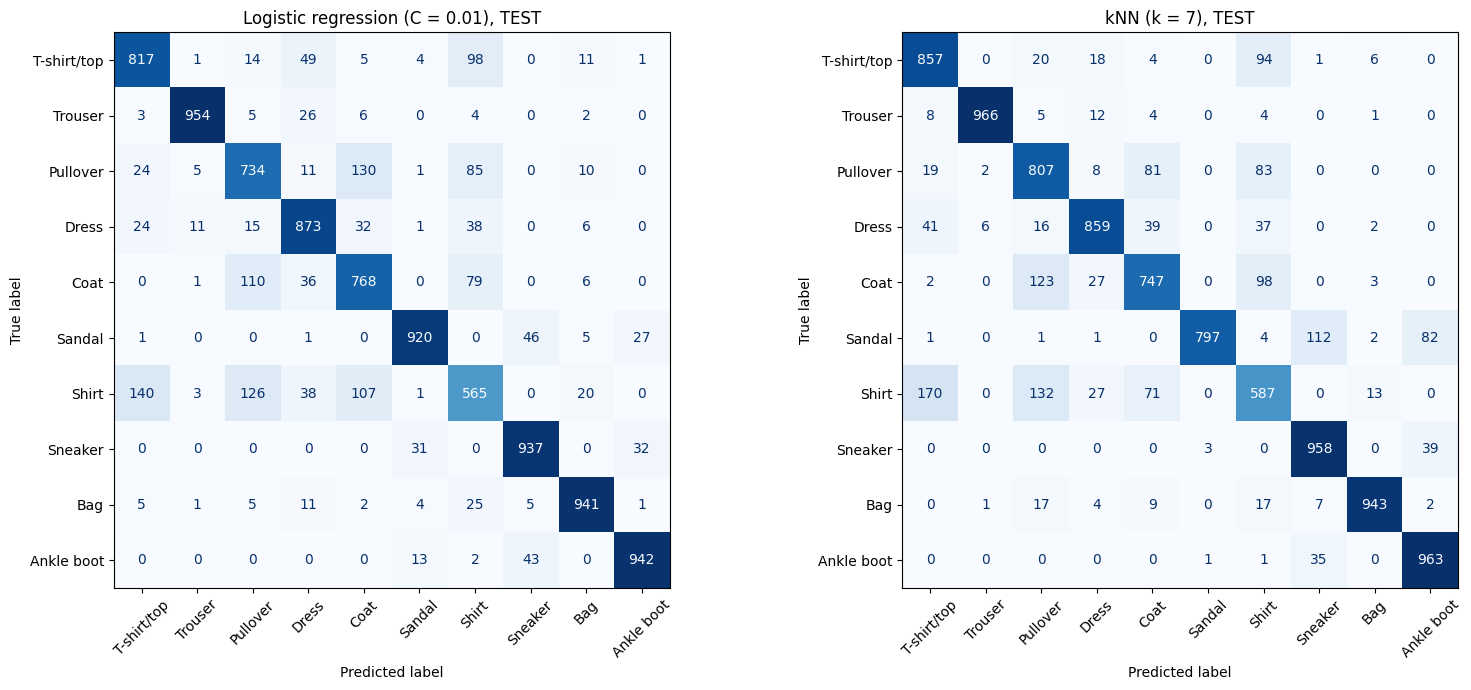

In [ ]:
# Part 1 (test plan): logistic regression C = 0.01 and kNN k = 7, evaluated once
lr_test_pred = final_log_reg.predict(X_test_scaled)

start = time.time()
knn_test_pred = final_knn.predict(X_test)
knn_test_time = time.time() - start

print(f"{'Model':<28} {'Validation':>10} {'Test':>8}")
print(f"{'Logistic regression (C=0.01)':<28} {final_lr_val_acc:>10.4f} {accuracy_score(y_test, lr_test_pred):>8.4f}")
print(f"{'kNN (k=7)':<28} {accuracy_score(y_val, knn_val_pred):>10.4f} {accuracy_score(y_test, knn_test_pred):>8.4f}")
print(f"\nkNN test prediction time: {knn_test_time:.1f} s")

print(f"\nLogistic regression (C = {best_C}), TEST set\n")
print(classification_report(y_test, lr_test_pred, target_names=class_names, digits=3))
print(f"\nkNN (k = {best_k}), TEST set\n")
print(classification_report(y_test, knn_test_pred, target_names=class_names, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
ConfusionMatrixDisplay.from_predictions(y_test, lr_test_pred, display_labels=class_names,
                                        xticks_rotation=45, cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"Logistic regression (C = {best_C}), TEST")
ConfusionMatrixDisplay.from_predictions(y_test, knn_test_pred, display_labels=class_names,
                                        xticks_rotation=45, cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title(f"kNN (k = {best_k}), TEST")
plt.tight_layout()
plt.show()

In [ ]:
# Part 1.5 (test plan): Shirt vs not Shirt, threshold t = 0.20 chosen on validation; t = 0.5 for reference
test_shirt_proba = final_log_reg.predict_proba(X_test_scaled)[:, shirt_col]
y_test_shirt = (y_test == SHIRT).astype(int)

def threshold_metrics(proba, y_true, t):
    pred = (proba >= t).astype(int)
    tp = np.sum((pred == 1) & (y_true == 1))
    fp = np.sum((pred == 1) & (y_true == 0))
    fn = np.sum((pred == 0) & (y_true == 1))
    return {"tp": tp, "fp": fp, "fn": fn,
            "precision": tp / (tp + fp) if (tp + fp) > 0 else 0.0,
            "recall": tp / (tp + fn),
            "cost": COST_FN * fn + COST_FP * fp}

print(f"Test shirts: {y_test_shirt.sum()}   non-shirts: {(y_test_shirt == 0).sum()}\n")
print(f"{'Set':<11} {'t':>5} {'TP':>5} {'FP':>5} {'FN':>5} {'Prec':>6} {'Recall':>7} {'Cost':>6}")
for label, proba, y_true in [("Validation", val_shirt_proba, y_val_shirt), ("Test", test_shirt_proba, y_test_shirt)]:
    for t in [0.20, 0.50]:
        m = threshold_metrics(proba, y_true, t)
        print(f"{label:<11} {t:>5.2f} {m['tp']:>5} {m['fp']:>5} {m['fn']:>5} "
              f"{m['precision']:>6.3f} {m['recall']:>7.3f} {m['cost']:>6}")

Test shirts: 1000   non-shirts: 9000

Set             t    TP    FP    FN   Prec  Recall   Cost
Validation   0.20   815   782   185  0.510   0.815   1707
Validation   0.50   549   189   451  0.744   0.549   2444
Test         0.20   759   855   241  0.470   0.759   2060
Test         0.50   484   223   516  0.685   0.484   2803


In [ ]:
# Part 2 (test plan): baseline MLP (main) and secondary checkpoints, loaded from the saved files
part2_checkpoints = [
    ("baseline", BASELINE_HIDDEN, "main"),
    ("small",    [32],            "secondary"),
    ("large",    [1024, 512],     "secondary"),
    ("lr_0.01",  BASELINE_HIDDEN, "secondary"),
    ("lr_0.5",   BASELINE_HIDDEN, "secondary"),
]

part2_test = {}
print(f"{'Checkpoint':<10} {'Role':<10} {'Val acc':>8} {'Test acc':>9} {'Test loss':>10}")
for name, hidden, role in part2_checkpoints:
    model = MLP(hidden).to(device)
    model.load_state_dict(torch.load(f"checkpoints/{name}.pt", map_location=device))
    val_loss, val_acc = evaluate(model, val_loader)        # should match Part 2's best validation accuracy
    test_loss, test_acc = evaluate(model, test_loader)
    part2_test[name] = {"val_acc": val_acc, "test_acc": test_acc, "test_loss": test_loss}
    print(f"{name:<10} {role:<10} {val_acc:>8.4f} {test_acc:>9.4f} {test_loss:>10.4f}")

Checkpoint Role        Val acc  Test acc  Test loss
baseline   main         0.8960    0.8819     0.3302
small      secondary    0.8746    0.8626     0.3829
large      secondary    0.8928    0.8772     0.3461
lr_0.01    secondary    0.8610    0.8422     0.4456
lr_0.5     secondary    0.8915    0.8813     0.3550


In [ ]:
# Part 3 (test plan): best-validation checkpoints of no regularisation and dropout 0.2, seeds 42, 43, 44
part3_test = {}
for name, (dropout, wd) in main_configs.items():
    part3_test[name] = []
    for seed in SEEDS:
        model = RegMLP(BASELINE_HIDDEN, dropout).to(device)   # same layout as when it was saved
        model.load_state_dict(torch.load(f"checkpoints/{name}_s{seed}.pt", map_location=device))
        _, val_acc = evaluate(model, val_loader)              # check: should match best_val_acc in Part 3
        _, test_acc = evaluate(model, test_loader)
        part3_test[name].append(test_acc)
        print(f"{name:<12} seed {seed}: val {val_acc:.4f}   test {test_acc:.4f}")

print(f"\n{'Config':<12} {'Test mean':>10} {'Test std':>9}")
for name, accs in part3_test.items():
    accs = np.array(accs)
    print(f"{name:<12} {accs.mean():>10.4f} {accs.std(ddof=1):>9.4f}")

none         seed 42: val 0.8727   test 0.8559
none         seed 43: val 0.8737   test 0.8592
none         seed 44: val 0.8754   test 0.8577
dropout_0.2  seed 42: val 0.8789   test 0.8611
dropout_0.2  seed 43: val 0.8785   test 0.8635
dropout_0.2  seed 44: val 0.8778   test 0.8638

Config        Test mean  Test std
none             0.8576    0.0017
dropout_0.2      0.8628    0.0015


In [ ]:
# Parts 4 and 5.1 (test plan): K = 10 centroids already fitted on the 3,000 clustering-train images; NOT refitted
Xc_test = pixels(test_data, cluster_test_indices)            # 1,000 clustering-test images, raw pixels 0-1
yc_test = test_data.targets[cluster_test_indices].numpy()    # labels for interpretation only

x_ct = test_data.data[cluster_test_indices].float().div(255.0).view(-1, 784).to(device)
with torch.no_grad():
    F_test = encoder(x_ct).cpu().numpy().astype(np.float64)  # frozen MLP features (same encoder as 5.1)

raw_test_clusters = km10.predict(Xc_test)       # nearest raw-pixel centroid
feat_test_clusters = kmF10.predict(F_test)      # nearest feature centroid

rows = [
    ("Silhouette (no labels)", k10(km_results)["val_sil"], silhouette_score(Xc_test, raw_test_clusters),
                               k10(feat_results)["val_sil"], silhouette_score(F_test, feat_test_clusters)),
    ("Purity vs classes", purity(raw_val_clusters, yc_val), purity(raw_test_clusters, yc_test),
                          purity(feat_val_clusters, yc_val), purity(feat_test_clusters, yc_test)),
    ("ARI vs classes", adjusted_rand_score(yc_val, raw_val_clusters), adjusted_rand_score(yc_test, raw_test_clusters),
                       adjusted_rand_score(yc_val, feat_val_clusters), adjusted_rand_score(yc_test, feat_test_clusters)),
]
print(f"{'K = 10':<24} {'Raw val':>8} {'Raw test':>9} {'Feat val':>9} {'Feat test':>10}")
for name, rv, rt, fv, ft in rows:
    print(f"{name:<24} {rv:>8.3f} {rt:>9.3f} {fv:>9.3f} {ft:>10.3f}")

K = 10                    Raw val  Raw test  Feat val  Feat test
Silhouette (no labels)      0.152     0.157     0.292      0.301
Purity vs classes           0.566     0.576     0.763      0.759
ARI vs classes              0.354     0.363     0.579      0.582


In [ ]:
# Part 5.2 (test plan): equal-weight average of logistic regression and baseline MLP probabilities
test_time = {}

start = time.time()
P_lr_test = final_log_reg.predict_proba(X_test_scaled)
test_time["LogReg"] = time.time() - start

start = time.time()
x_test_mlp = test_data.data.float().div(255.0).view(-1, 784).to(device)
with torch.no_grad():
    P_mlp_test = torch.softmax(feat_model(x_test_mlp), dim=1).cpu().numpy()
test_time["MLP"] = time.time() - start

pred_lr_test = P_lr_test.argmax(axis=1)
pred_mlp_test = P_mlp_test.argmax(axis=1)
pred_ens_test = ((P_lr_test + P_mlp_test) / 2).argmax(axis=1)       # same fixed rule as validation

test_preds = {"LogReg": pred_lr_test, "kNN": knn_test_pred, "MLP": pred_mlp_test, "Ensemble": pred_ens_test}
val_preds = {"LogReg": pred_lr, "kNN": pred_knn, "MLP": pred_mlp, "Ensemble": pred_ens}

print(f"{'Model':<10} {'Validation':>10} {'Test':>8}")
for name in test_preds:
    print(f"{name:<10} {accuracy_score(y_val, val_preds[name]):>10.4f} {accuracy_score(y_test, test_preds[name]):>8.4f}")

# Per-class recall on test, ensemble vs MLP
print(f"\n{'Class':<12} {'MLP':>7} {'Ensemble':>9} {'Ens - MLP':>10}")
for c, cname in enumerate(class_names):
    mask = (y_test == c)
    r_mlp, r_ens = np.mean(pred_mlp_test[mask] == c), np.mean(pred_ens_test[mask] == c)
    print(f"{cname:<12} {r_mlp:>7.3f} {r_ens:>9.3f} {r_ens - r_mlp:>+10.3f}")

# Fixed / broken relative to the MLP
ens_ok, mlp_ok = (pred_ens_test == y_test), (pred_mlp_test == y_test)
print(f"\nvs MLP on test: fixed {np.sum(ens_ok & ~mlp_ok)}   broken {np.sum(~ens_ok & mlp_ok)}   "
      f"net {np.sum(ens_ok & ~mlp_ok) - np.sum(~ens_ok & mlp_ok):+d}")
print(f"Prediction time on 10,000 test images: LogReg {test_time['LogReg']:.2f} s, MLP {test_time['MLP']:.2f} s, "
      f"ensemble {test_time['LogReg'] + test_time['MLP']:.2f} s")

Model      Validation     Test
LogReg         0.8640   0.8451
kNN            0.8617   0.8484
MLP            0.8960   0.8819
Ensemble       0.8931   0.8781

Class            MLP  Ensemble  Ens - MLP
T-shirt/top    0.903     0.874     -0.029
Trouser        0.973     0.973     +0.000
Pullover       0.734     0.741     +0.007
Dress          0.902     0.904     +0.002
Coat           0.886     0.852     -0.034
Sandal         0.960     0.960     +0.000
Shirt          0.591     0.608     +0.017
Sneaker        0.941     0.942     +0.001
Bag            0.959     0.964     +0.005
Ankle boot     0.970     0.963     -0.007

vs MLP on test: fixed 137   broken 175   net -38
Prediction time on 10,000 test images: LogReg 0.05 s, MLP 0.22 s, ensemble 0.27 s


# Part 6: Final synthesis

**(O)** observation, **(I)** interpretation, **(H)** hypothesis, **(C)** conclusion. "Test" refers to the final
evaluation cells.

### Claim 1: Shirt is the hardest class for every method
- **(O)** Shirt had the lowest recall for both classifiers on validation (0.622; Part 1.2) and test (0.565 and 0.587;
  Test, Part 1). K-means spread shirts over four clusters (Part 4.2), MLP features left them mixed with Pullover and
  Coat (purity 0.37; Part 5.1), and the ensemble only moved errors between tops (Test, Part 5.2).
- **(I)** At 28 × 28 pixels, shirts differ from other tops mainly in small details such as collars and buttons.
- **(H)** A small CNN, which uses local image structure, should raise Shirt recall more than other classes.
- **(C)** Classifiers and clustering agree that the hardest boundary is among upper-body garments.

### Claim 2: Capacity improved training fit; early stopping helped more than dropout
- **(O)** Training loss fell from 0.2874 (small) to 0.1883 (large), but test accuracy was 0.8626, 0.8819 (baseline)
  and 0.8772 (Part 2.2; Test, Part 2). Dropout raised test accuracy from 0.8576 ± 0.0017 to 0.8628 ± 0.0015, for every
  seed, while the best checkpoint added about 2.5–2.7 points over late training (Part 3; Test, Part 3).
- **(I)** Extra parameters went into fitting the training data; the large network had also not finished training.
- **(C)** Dropout's gain is consistent (about three times the seed standard deviation) but small, and early stopping
  was the stronger regulariser.

### Claim 3: The representation mattered more than the algorithm, but labels shaped it
- **(O)** Logistic regression and kNN on raw pixels tied on test (84.51% and 84.84%), while the MLP reached 88.19%.
  With the same K-means protocol, MLP features raised ARI against the classes from 0.363 to 0.582 on the test subset
  (Test, Parts 1, 2, 4 and 5.1).
- **(I)** Raw-pixel distance is dominated by outline and brightness (Part 4.2); the MLP features ignore brightness
  because they were learned with the labels (Part 5.1).
- **(H)** Logistic regression on frozen MLP features should approach the MLP's accuracy, which would separate the
  effect of the representation from that of the classifier, something this design cannot do.

### Claim 4: The ensemble did not justify its cost
- **(O)** The ensemble scored below the MLP alone on validation (89.31% vs 89.60%) and test (87.81% vs 88.19%), fixing
  137 test images but breaking 175 (Part 5.2; Test, Part 5.2).
- **(I)** Its members were unequal: logistic regression was about 3.7 points behind the MLP on test.
- **(H)** Averaging models of similar accuracy, such as the three dropout seeds from Part 3, should help more.
- **(C)** Small extra cost (0.27 s vs 0.22 s), no gain: not justified for this pair.

**Generalisation and scaling.** **(I)** Fine-grained class overlap is likely general; the brightness effect depends
on Fashion-MNIST's centred greyscale images. **(H)** Growing data with model size should keep the train–validation
gap small: the same logistic regression had a gap of 0.1515 on 10,000 images but 0.0331 on 50,000 (Part 1.4).
**(O)** Validation and test disagreed once, on the order of logistic regression and kNN, but both gaps were small
(Test, Part 1).